## Лабораторная работа № 1 
## Выполнение разведочного анализа больших данных с использованием фреймворка Apache Spark

### Часть 2

В данной части работы рассмотрены:
* разведочный анализ данных (exploratory data analysis, EDA);
* обработка пропущенных значений;
* обработка выбросов и аномальных значений;
* визуализация распределений признаков;
* работа с DataFrame API фреймворка `Apache Spark`.

Подключаем необходимые библиотеки.

In [1]:
import os
from pyspark.sql import SparkSession, DataFrame
from pyspark import SparkConf
from pyspark.sql.functions import (
    col,
    lit,
    when,
    count,
    mean,
    sum,
    desc,
    floor,
    corr,
    expr,
    trim,
    lower,
    length,
    substring,
    month,
    dayofweek,
    hour
)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Сформируем объект конфигурации для `Apache Spark`, указав необходимые параметры. Конфигурация совпадает с первой частью работы: расчёт ведётся на кластере `Hadoop YARN`, таблицы читаются из каталога `Apache Iceberg`.

In [2]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")
    
    conf = SparkConf()
    conf.setAppName("lab 1 US Accidents. Part 2")
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    conf.set("spark.executor.cores", "8")
    conf.set("spark.executor.instances", "2")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
    conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

    return conf

Создаём сам объект конфигурации.

In [3]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`. В процессе создания сессии происходит подключение к кластеру `Apache Hadoop`, что может занять некоторое время.

In [4]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user7/.ivy2/cache
The jars for the packages stored in: /home/user7/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-767db666-a4f0-4540-b032-80ad4fd1a7d5;1.0
	confs: [default]


	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 627ms :: artifacts dl 24ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-767db666-a4f0-4540-b032-80ad4fd1a7d5
	confs: [default]
	0 artifacts copied, 1 already retrieved (0kB/26ms)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/26 15:53:26 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


26/10/26 15:53:45 WARN Client: Same path resource file:///home/user7/.ivy2/jars/org.apache.iceberg_iceberg-spark-runtime-3.5_2.12-1.6.0.jar added multiple times to distributed cache.


Укажем базу данных, которая была создана в первой части лабораторной работы.

In [5]:
database_name = "otpushchennikov_database"
table_name = "otpushchennikov_us_accidents"

Установим созданную базу данных как текущую.

In [6]:
spark.catalog.setCurrentDatabase(database_name)

Прочитаем сохранённую в предыдущей части работы таблицу и загрузим её в `Spark DataFrame`.

In [7]:
df = spark.table(table_name)

Выведем прочитанную таблицу на экран.

In [8]:
df.show(3, truncate=25)

26/10/26 15:54:42 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+---------+--------+-------------------+-------------------+---------+----------+------------+------------------+--------+-----------+-----+-------+----------+------------+-------------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+-----+--------+--------+--------+-------+-------+----------+-------+-----+--------------+------------+--------------+--------------+-----------------+---------------------+------------+
|       ID|Severity|         Start_Time|           End_Time|Start_Lat| Start_Lng|Distance(mi)|            Street|    City|     County|State|Zipcode|  Timezone|Airport_Code|  Weather_Timestamp|Temperature(F)|Wind_Chill(F)|Humidity(%)|Pressure(in)|Visibility(mi)|Wind_Direction|Wind_Speed(mph)|Precipitation(in)|Weather_Condition| Bump|Crossing|Give_Way|Junction|No_Exit|Railway|Roundabout|Station| Stop|Traffic_Signal|Turning_Loop|Sunrise_Sunset|Civil_Twilight|Nautical_Twilight|Astronom

Посмотрим на схему данных.

In [9]:
df.printSchema()

root
 |-- ID: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- Distance(mi): float (nullable = true)
 |-- Street: string (nullable = true)
 |-- City: string (nullable = true)
 |-- County: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Airport_Code: string (nullable = true)
 |-- Weather_Timestamp: timestamp (nullable = true)
 |-- Temperature(F): float (nullable = true)
 |-- Wind_Chill(F): float (nullable = true)
 |-- Humidity(%): float (nullable = true)
 |-- Pressure(in): float (nullable = true)
 |-- Visibility(mi): float (nullable = true)
 |-- Wind_Direction: string (nullable = true)
 |-- Wind_Speed(mph): float (nullable = true)
 |-- Precipitation(in): float (nullable = true)
 |-- Weather_Condition: 

Вычислим количество строк в датафрейме.

In [10]:
df.count()

7728394

Видим 7 728 394 строки -- ровно столько записей содержал исходный CSV-файл, то есть при сохранении в таблицу `Apache Iceberg` ни одна запись не потеряна.

Дальнейший анализ представляет собой многократные проходы по одним и тем же данным: подсчёт пропусков, расчёт квартилей и сводных статистик, построение графиков. Чтобы не перечитывать таблицу из `HDFS` на каждом шаге, зафиксируем датафрейм в памяти исполнителей.

In [11]:
df = df.cache()

### Пропущенные значения: общий обзор

Первым делом имеет смысл оценить масштаб проблемы по всем столбцам сразу. Введём функцию, которая одним проходом по данным вычисляет для каждого столбца число пропущенных значений и его долю, и возвращает результат в виде `pandas DataFrame`, отсортированного по убыванию доли пропусков.

In [12]:
def missing_overview(data: DataFrame) -> pd.DataFrame:
    """
    Подсчет количества и доли пропущенных значений для всех столбцов
    датафрейма за один проход по данным.

    Args:
        data (DataFrame): DataFrame, содержащий данные.

    Returns:
        pd.DataFrame: Таблица со столбцами `column`, `nulls`, `share`,
            отсортированная по убыванию доли пропусков.
    """
    total = data.count()
    counters = [count(when(col(name).isNull(), lit(True))).alias(str(index))
                for index, name in enumerate(data.columns)]
    counts = data.agg(*counters).collect()[0].asDict()

    rows = [
        (name, int(counts[str(index)]), 100.0 * int(counts[str(index)]) / total)
        for index, name in enumerate(data.columns)
    ]
    overview = pd.DataFrame(rows, columns=["column", "nulls", "share"])
    return overview.sort_values("share", ascending=False).reset_index(drop=True)

In [13]:
missing = missing_overview(df)
missing[missing["share"] > 0].to_string(index=False)

'               column   nulls     share\n    Precipitation(in) 2203586 28.512858\n        Wind_Chill(F) 1999019 25.865904\n      Wind_Speed(mph)  571233  7.391355\n       Visibility(mi)  177098  2.291524\n       Wind_Direction  175206  2.267043\n          Humidity(%)  174144  2.253301\n    Weather_Condition  173459  2.244438\n       Temperature(F)  163853  2.120143\n         Pressure(in)  140679  1.820288\n    Weather_Timestamp  120228  1.555666\n    Nautical_Twilight   23246  0.300787\n       Civil_Twilight   23246  0.300787\n       Sunrise_Sunset   23246  0.300787\nAstronomical_Twilight   23246  0.300787\n         Airport_Code   22635  0.292881\n               Street   10869  0.140637\n             Timezone    7808  0.101030\n              Zipcode    1915  0.024779\n                 City     253  0.003274'

Картина следующая. Пропуски сосредоточены в метеорологических признаках: сильнее всего пострадали `Precipitation(in)` (28,51% пропусков) и `Wind_Chill(F)` (25,87%), затем идёт `Wind_Speed(mph)` (7,39%), остальные метеопризнаки содержат около 2% пропусков. Признаки места события и времени почти чистые: максимум -- 0,3% у четырёх признаков светового времени суток и 0,29% у `Airport_Code`. Ни одного пропуска нет в идентификаторе, признаке тяжести, координатах, времени начала и окончания происшествия, протяжённости перекрытого участка, длительности происшествия и во всех булевых признаках инфраструктуры.

Нагляднее всего это видно на диаграмме долей пропусков.

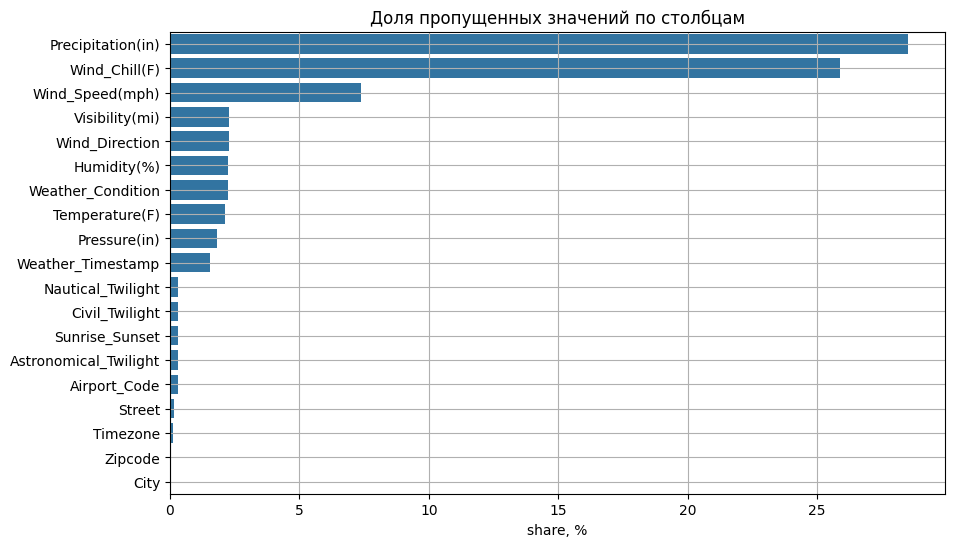

In [14]:
plot_data = missing[missing["share"] > 0]
plt.figure(figsize=(10, 6))
sns.barplot(x="share", y="column", data=plot_data)
plt.title("Доля пропущенных значений по столбцам")
plt.xlabel("share, %")
plt.ylabel("")
plt.grid(True)
plt.show()

### Анализ столбца `ID`

Столбец `ID` -- идентификатор происшествия, кандидат на первичный ключ таблицы. Проверим, что все значения соответствуют ожидаемому формату `A-<номер>`, как в исходном CSV-файле.

In [15]:
(df.select("ID")
  .filter(~col("ID").rlike("^[A-Z]+-[0-9]+$"))
  .count())

0

Неподходящих под шаблон значений нет, поэтому -- в отличие от примера из методических указаний, где ключ VIN приходилось отсеивать по регулярному выражению -- здесь фильтровать нечего. Проверим наличие дубликатов ключа.

In [16]:
(df.groupBy("ID")
   .count()
   .where("count > 1")
   .count())

0

Дубликатов ключа также нет: каждая из 7 728 394 записей уникальна (число различных значений `ID` совпадает с числом строк). Таким образом, на уровне ключа данные чистые, и удалять строки не требуется.

In [17]:
df.select("ID").distinct().count()

7728394

### Анализ столбца `Severity`

Степень тяжести происшествия -- упорядоченный категориальный признак, который в дальнейшем будет использоваться как цель задачи классификации. Проверим его на наличие пропущенных значений и посмотрим на распределение.

In [18]:
def count_nulls(data: DataFrame,
                column_name: str) -> None:
    """
    Подсчет количества null и not null значений в указанном столбце.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для подсчета null и not null значений.
    
    Returns:
        None
    """
    # Подсчет количества null значений в указанном столбце
    null_counts = data.select(
        sum(col(column_name).isNull().cast("int"))
    ).collect()[0][0]

    # Подсчет количества not null значений в указанном столбце
    not_null_counts = data.select(
        sum(col(column_name).isNotNull().cast("int"))
    ).collect()[0][0]

    # Вывод результатов
    print(f"Число колонок с NULL: {null_counts} "
          f"({100 * null_counts / (null_counts + not_null_counts):.2f}%)")

In [19]:
count_nulls(data=df, column_name="Severity")

Число колонок с NULL: 0 (0.00%)


Пропусков нет. Введём функцию расчёта и визуализации распределения категориальных признаков и воспользуемся ею.

In [20]:
def plot_cat_distribution(data: DataFrame,
                          column_name: str,
                          top_n: int = 20) -> None:
    """
    Построение распределения категориального признака.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для группировки.
        top_n (int): Количество топ-значений для отображения.
    
    Returns:
        None
    """
    # Группировка данных по столбцу и подсчет количества
    categories = (
        data
        .groupBy(column_name)
        .count()
        .orderBy("count", ascending=False)
    )
    
    print(f"Количество категорий признака {column_name}: {categories.count()}")

    categories = (
        categories
        .limit(top_n)
        .toPandas()
    )
    
    # Визуализация с использованием Seaborn
    plt.figure(figsize=(10, 6))
    sns.barplot(x=column_name, y="count", data=categories)
    plt.title(f"Barplot of \"{column_name}\" counts")
    plt.xlabel(column_name)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

Количество категорий признака Severity: 4


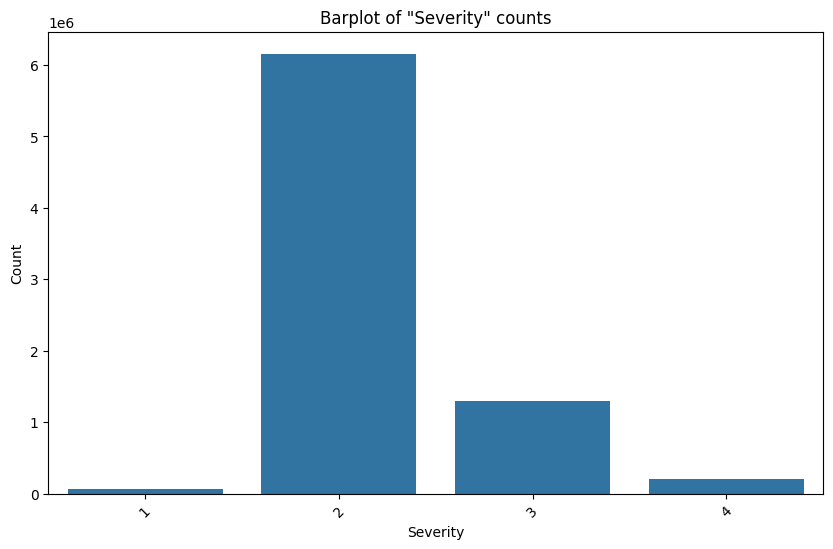

In [21]:
plot_cat_distribution(data=df, column_name="Severity")

Признак принимает четыре значения от 1 (незначительное происшествие) до 4 (серьёзное). Распределение крайне несбалансированно: происшествий средней тяжести (`Severity = 2`) -- 6 156 981 (79,7%), лёгких (`Severity = 1`) -- всего 67 366 (0,9%), тяжёлых (`Severity = 3`) -- 1 299 337 (16,8%) и самых серьёзных (`Severity = 4`) -- 204 710 (2,6%). Это важно учитывать при постановке задачи классификации: классы нужно будет либо уравновешивать, либо оценивать модель метриками, устойчивыми к дисбалансу.

### Анализ столбца `Duration_min`

Длительность происшествия -- количественный признак, вычисленный в первой части работы как разность временны́х меток. Он будет целью задачи регрессии, поэтому уделим ему особое внимание.

In [22]:
count_nulls(data=df, column_name="Duration_min")

Число колонок с NULL: 0 (0.00%)


Пропусков нет, поскольку пропусков нет ни в одной из исходных меток. Введём функцию расчёта статистик и построения диаграммы «ящик с усами» по правилу межквартильного размаха.

In [23]:
def plot_boxplots(data: DataFrame,
                  columns: list[str],
                  sample_fraction: float = 0.1) -> None:
    """
    Построение boxplot для нескольких столбцов в PySpark DataFrame.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        columns (list of str): Список имен столбцов для построения boxplot.
        sample_fraction (float): Доля данных для семплирования выбросов.
    
    Returns:
        None
    """
    box_data = []

    for column in columns:
        # Вычисление квантилей
        quantiles = data.approxQuantile(column, [0.25, 0.5, 0.75], 0.01)
        q1, median, q3 = quantiles

        # Вычисление IQR и границ усов
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        # Вычисление минимального и максимального значений
        min_value = data.agg({column: "min"}).collect()[0][0]
        mean_value = data.agg({column: "mean"}).collect()[0][0]
        std_value = data.agg({column: "stddev"}).collect()[0][0]
        max_value = data.agg({column: "max"}).collect()[0][0]

        # Фильтрация выбросов
        outliers_df = data.filter((col(column) < lower_bound) | (col(column) > upper_bound))
        outliers_count = outliers_df.count()

        # Ограничение усов минимальным и максимальным значениями
        lower_bound = max(lower_bound, min_value)
        upper_bound = min(upper_bound, max_value)

        # Семплирование выбросов
        outliers = []
        if outliers_count > 0:
            sampled_outliers_df = outliers_df.sample(sample_fraction)
            outliers = (
                sampled_outliers_df
                .select(column)
                .limit(1000)
                .collect()
            )
            outliers = [row[column] for row in outliers]

        # Вывод статистических характеристик
        print(f"{column}: {outliers_count} значений ("
              f"{100 * outliers_count / data.count():.2f}%) вне границ "
              f"[{lower_bound:.2f}, {upper_bound:.2f}]")
        print(f"  Минимальное значение:          {min_value:.2f}")
        print(f"  Среднее значение:              {mean_value:.2f}")
        print(f"  Среднеквадратичное отклонение: {std_value:.2f}")
        print(f"  Первый квартиль:               {q1:.2f}")
        print(f"  Медиана:                       {median:.2f}")
        print(f"  Третий квартиль:               {q3:.2f}")
        print(f"  Максимальное значение:         {max_value:.2f}")

        # Подготовка данных для axes.bxp
        box_data.append({
            'whislo': lower_bound,  # Нижняя граница усов
            'q1': q1,               # Первый квартиль
            'med': median,          # Медиана
            'q3': q3,               # Третий квартиль
            'whishi': upper_bound,  # Верхняя граница усов
            'fliers': outliers      # Выбросы
        })

    # Построение boxplot
    fig, ax = plt.subplots(figsize=(20, 6))
    ax.bxp(box_data,
           vert=False,
           positions=range(1, len(columns) + 1), widths=0.5)
    ax.set_yticks(range(1, len(columns) + 1))
    ax.set_yticklabels(columns)
    ax.set_xlabel('Value')
    ax.set_title('Boxplots')
    ax.grid(True)
    plt.show()

Duration_min: 731676 значений (9.47%) вне границ [1.22, 265.75]
  Минимальное значение:          1.22
  Среднее значение:              444.42
  Среднеквадратичное отклонение: 13512.29
  Первый квартиль:               31.00
  Медиана:                       74.78
  Третий квартиль:               124.90
  Максимальное значение:         2812939.00


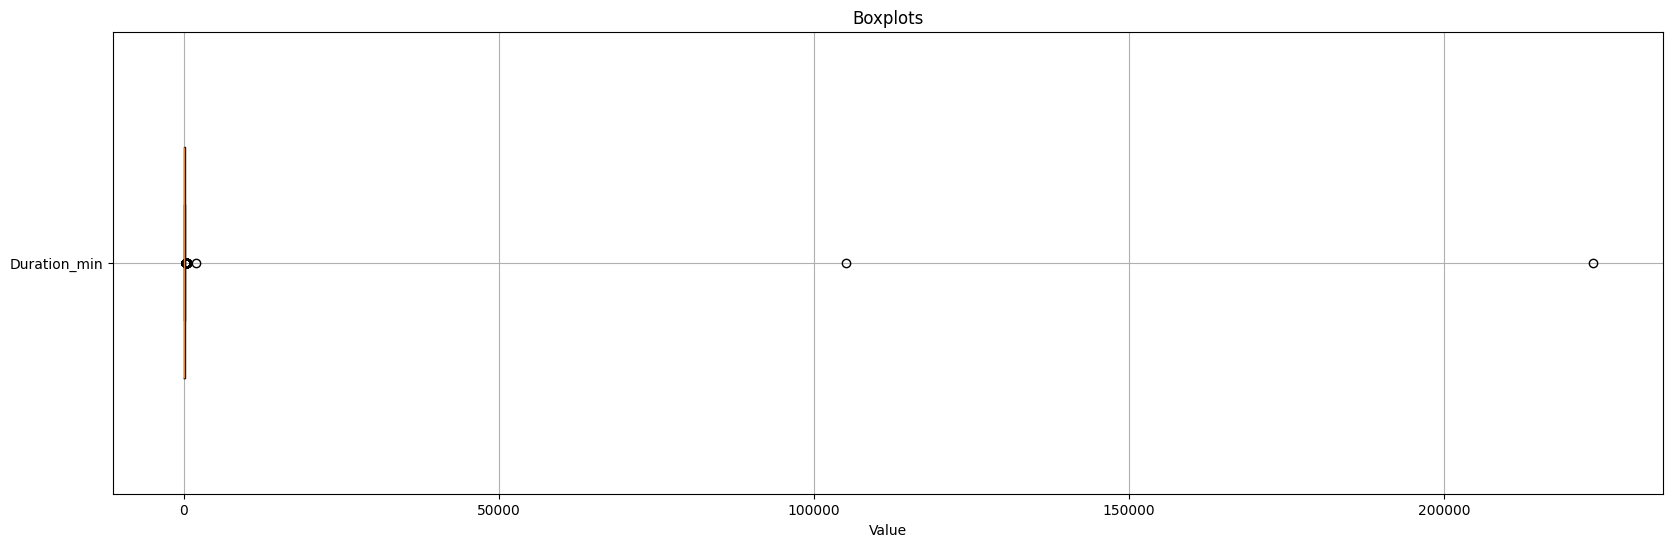

In [24]:
plot_boxplots(data=df, columns=["Duration_min"])

Медиана длительности -- 75 минут, при этом среднее равно 444 минутам, а максимальное значение достигает 2 812 939 минут -- это чуть меньше пяти с половиной лет. Столь сильный перекос среднего относительно медианы означает, что распределение имеет очень тяжёлый правый хвост. Построим гистограмму распределения, для чего введём отдельную функцию.

In [25]:
def plot_quant_distribution(data: DataFrame,
                            column: str,
                            num_bins: int = 200) -> None:
    """
    Построение гистограммы для количественной переменной с
    использованием PySpark и Seaborn.

    Args:
        data (DataFrame): DataFrame с данными.
        column (str): Название колонки с количественной переменной.
        num_bins (int): Количество бинов для гистограммы.

    Returns:
        None
    """
    data = data.filter(col(column).isNotNull())

    # Находим минимальное и максимальное значения колонки
    min_value = data.agg({column: "min"}).collect()[0][0]
    max_value = data.agg({column: "max"}).collect()[0][0]

    # Размер бина
    bin_size = (max_value - min_value) / num_bins

    # Добавляем колонку с номером бина
    data = data.withColumn(
        "bin",
        floor((col(column) - min_value) / bin_size)
    )

    # Группируем по номеру бина и считаем количество строк в каждом бине
    bin_counts = data.groupBy("bin").count()

    # Преобразуем результат в Pandas DataFrame для построения гистограммы
    bin_counts_pd = bin_counts.limit(1000).toPandas()
    
    # Создаем массив границ бинов
    bin_edges = [min_value + i * bin_size for i in range(num_bins + 2)]
    
    # Преобразуем номера бинов в центры бинов
    bin_centers = [
        (bin_edges[i] + bin_edges[i + 1]) / 2 for i in range(num_bins + 1)
    ]
    
    # Добавляем центры бинов в Pandas DataFrame
    bin_counts_pd['bin_center'] = bin_counts_pd['bin'].apply(
        lambda x: bin_centers[int(x)]
    )
    
    # Построение гистограммы с использованием Seaborn
    plt.figure(figsize=(20, 6))
    sns.histplot(data=bin_counts_pd, x="bin_center",
                 weights="count", kde=True, bins=num_bins + 1)
    plt.xlabel("Value")
    plt.ylabel("Count")
    plt.title(f"Распределение количественного признака \"{column}\"")
    plt.grid(True)
    plt.show()

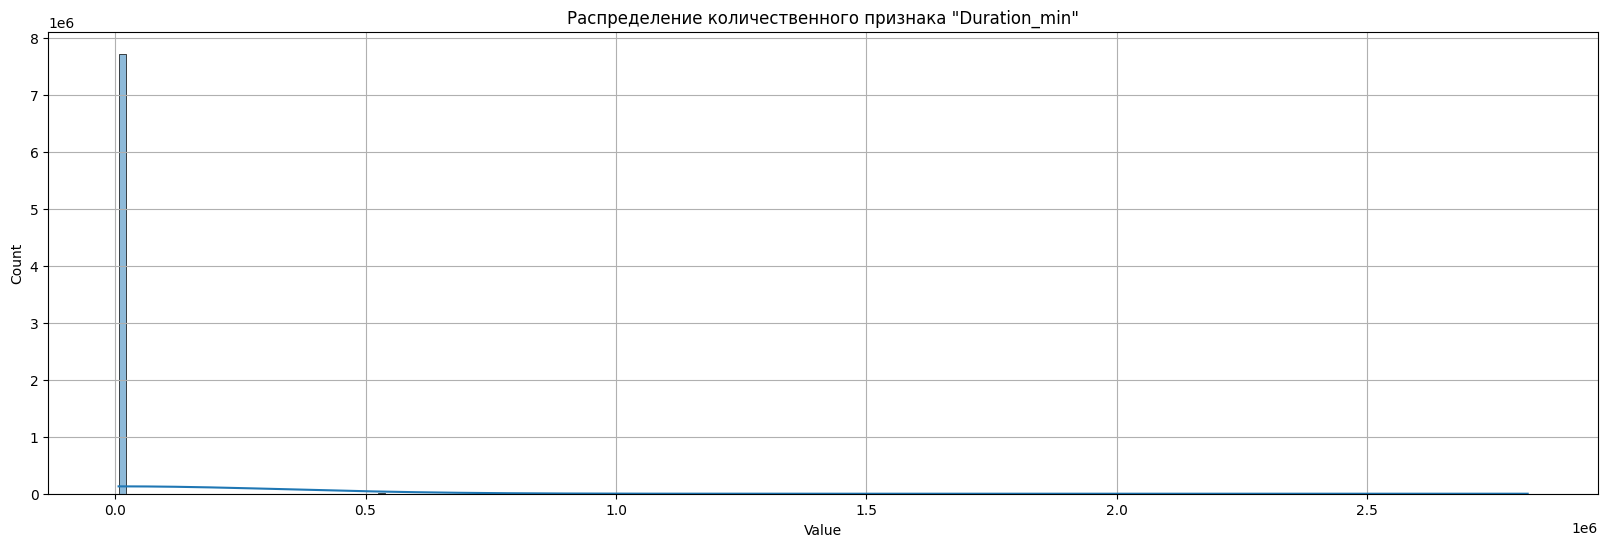

In [26]:
plot_quant_distribution(data=df, column="Duration_min")

На гистограмме практически все данные сосредоточены у левого края, а правее видны лишь отдельные всплески: из-за единичных экстремальных значений ширина бина оказывается равной примерно 14 тысяч минут, и основной массе данных (длительность до двух суток) соответствует самый первый бин. Такое представление бесполезно, поэтому выбросы нужно обрезать.

Сравним правило межквартильного размаха с физическим смыслом признака. По правилу IQR верхняя граница «усов» равна $Q_3 + 1{,}5 \cdot IQR = 124{,}9 + 1{,}5 \cdot 93{,}9 \approx 265{,}8$ минуты, то есть выбросом считается происшествие длительностью более 4,5 часов -- а таких в данных 731 676 записей, 9,47%, то есть почти каждая десятая. Требование удалить их привело бы к потере слишком большого объёма наблюдений, и оно некорректно: длительная пробка на трассе -- не аномалия, а обычное событие.

Обратимся вместо IQR к предметной границе. Посмотрим, сколько записей содержит длительность больше суток и больше двух суток.

In [27]:
total = df.count()
for limit_minutes in (1440, 2880, 10080):
    n = df.filter(col("Duration_min") > limit_minutes).count()
    print(f"Длительность больше {limit_minutes} мин: {n} записей "
          f"({100.0 * n / total:.3f}%)")

Длительность больше 1440 мин: 34981 записей (0.453%)


Длительность больше 2880 мин: 10882 записей (0.141%)


Длительность больше 10080 мин: 6824 записей (0.088%)


Отсечение значений длительностью более двух суток (2880 минут) затрагивает 10 882 записи -- 0,14% данных, причём именно эти записи означают, что метка окончания происшествия проставлена через много часов или даже лет после начала: такие значения `End_Time` невозможно объяснить дорожным происшествием. Обрежем хвост, сохранив сами строки: это стандартный приём виндзоризации, при котором выбросы заменяются границей, а не удаляются.

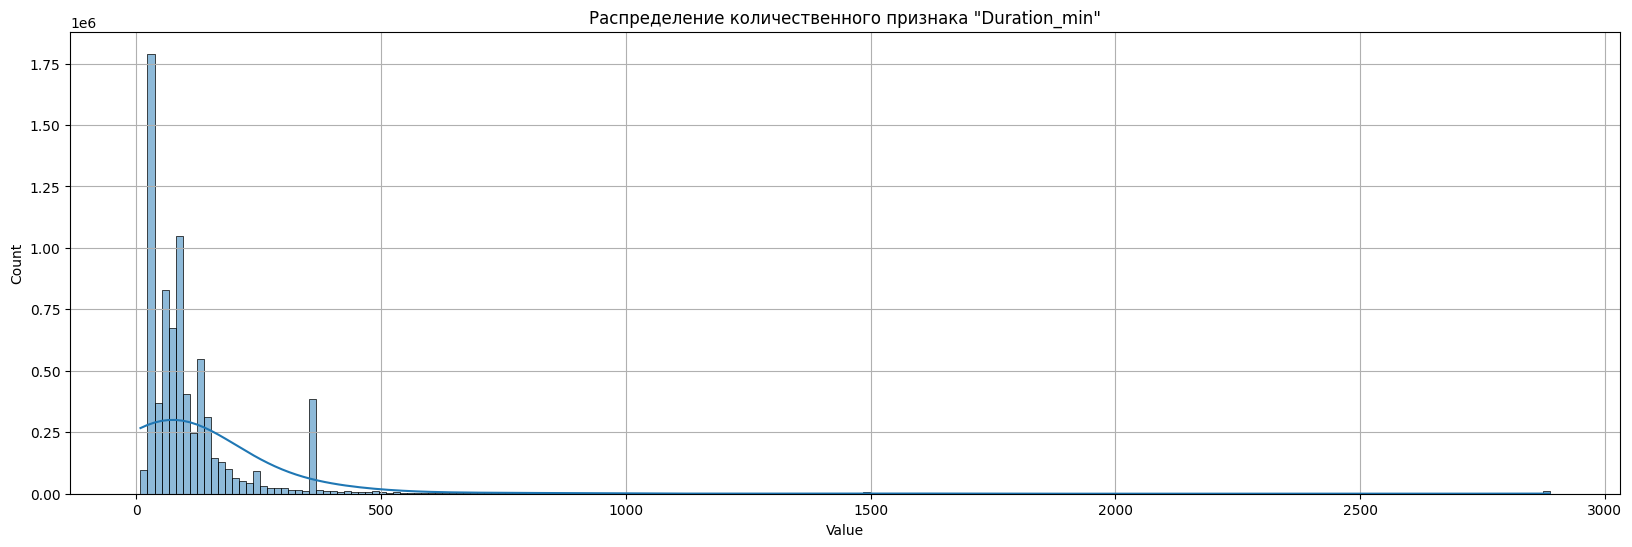

In [28]:
DURATION_CAP = 2880.0
df = df.withColumn(
    "Duration_min",
    when(col("Duration_min") > DURATION_CAP, DURATION_CAP).otherwise(col("Duration_min"))
)
plot_quant_distribution(data=df, column="Duration_min")

Теперь распределение читается корректно: основной массив данных сосредоточен в начале диапазона, медиана составляет около 75 минут, подавляющее большинство происшествий завершается в течение шести часов, а правый хвост ограничен двумя сутками. Среднее после обрезки равно 112,8 минуты вместо 444,4 минуты до неё -- это и есть оценка вклада экстремальных значений.

### Анализ столбца `Distance(mi)`

Протяжённость перекрытого участка дороги -- количественный признак в милях. Пропусков в нём нет (0%), проверим наличие выбросов.

In [29]:
count_nulls(data=df, column_name="Distance(mi)")

Число колонок с NULL: 0 (0.00%)


Distance(mi): 969428 значений (12.54%) вне границ [0.00, 1.15]
  Минимальное значение:          0.00
  Среднее значение:              0.56
  Среднеквадратичное отклонение: 1.78
  Первый квартиль:               0.00
  Медиана:                       0.03
  Третий квартиль:               0.46
  Максимальное значение:         441.75


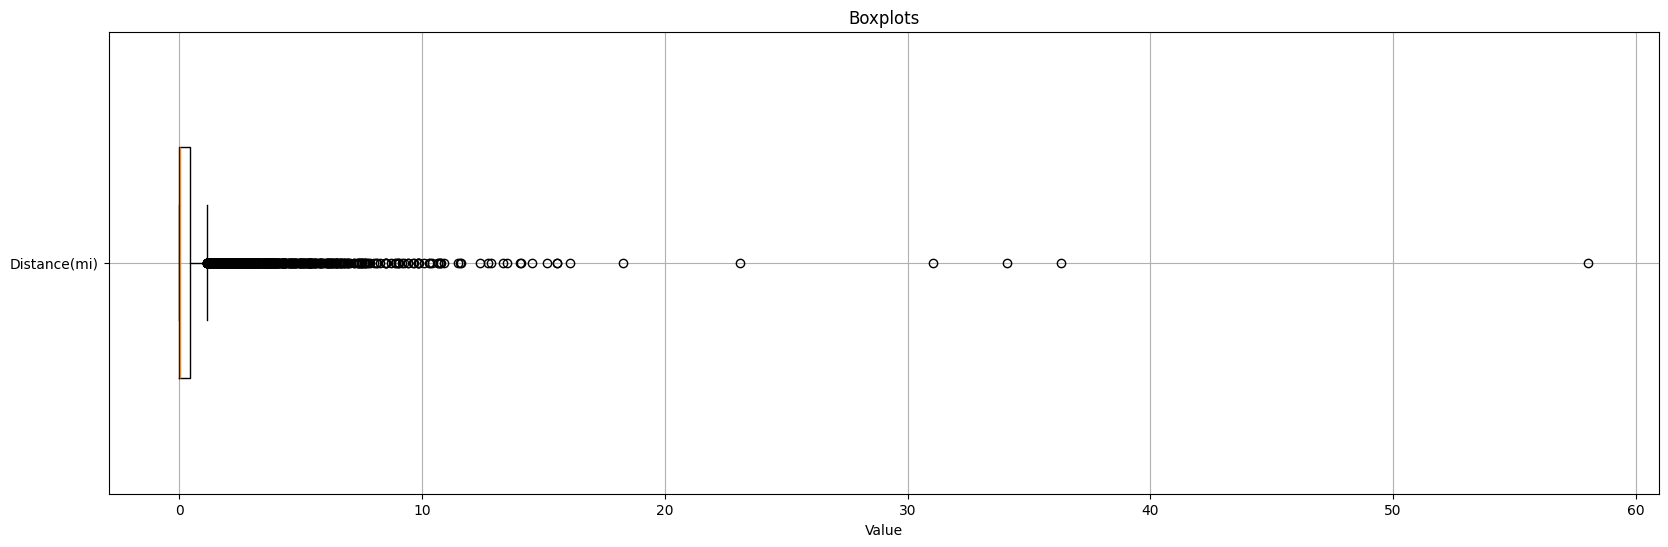

In [30]:
plot_boxplots(data=df, columns=["Distance(mi)"])

Правило IQR здесь даёт нерелевантный результат: первый квартиль равен 0,00 мили, поэтому нижняя граница «усов» получается отрицательной, а верхней границей оказывается $Q_3 + 1{,}5 \cdot IQR = 0{,}46 + 1{,}5 \cdot 0{,}46 \approx 1{,}15$ мили -- вне неё попадают 969 428 значений, 12,54%, хотя перекрытие полосы на милю и более -- обычная ситуация при крупном происшествии. Максимум же, 441,75 мили, действительно физически сомнителен: столь длинный перекрытый участок регистрируется при масштабных авариях, и таких записей совсем немного.

Поэтому и здесь воспользуемся предметной границей: оставим значения не более 60 миль (около 97 км).

In [31]:
(df.filter(col("Distance(mi)") > 60).count(),
df.filter(col("Distance(mi)") > 100).count())

(416, 86)

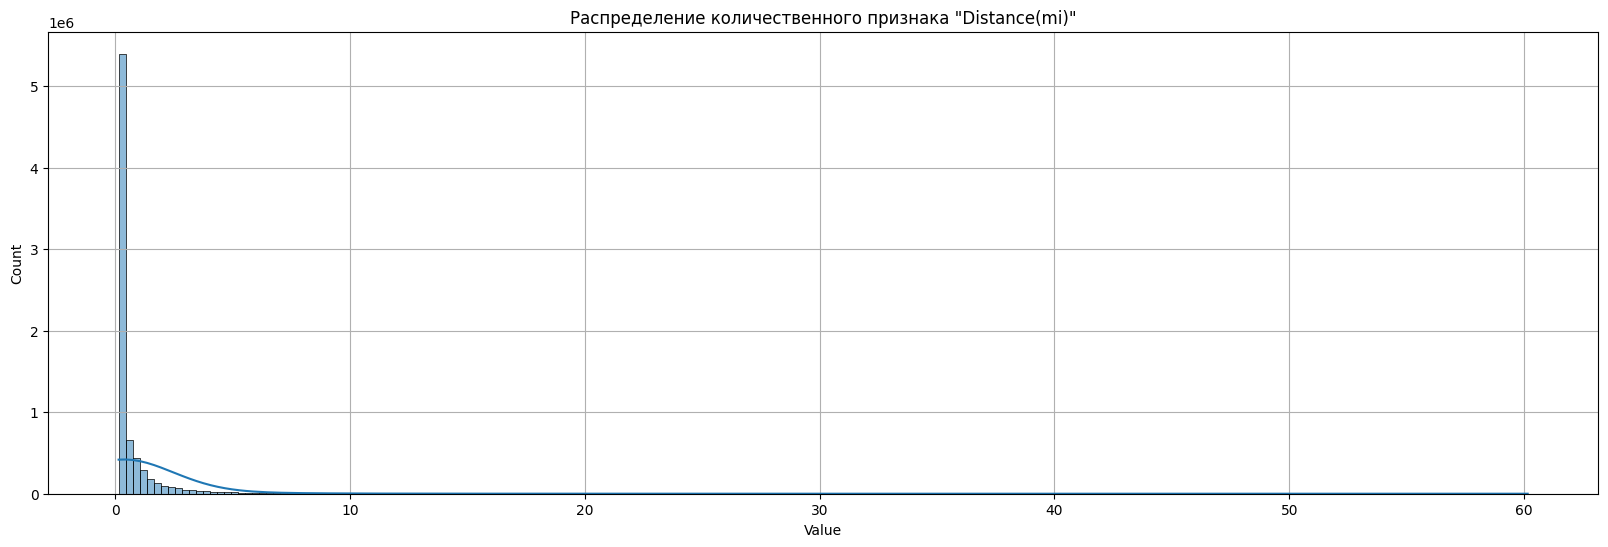

In [32]:
DISTANCE_CAP = 60.0
df = df.withColumn(
    "Distance(mi)",
    when(col("Distance(mi)") > DISTANCE_CAP, DISTANCE_CAP).otherwise(col("Distance(mi)")
    )
)
plot_quant_distribution(data=df, column="Distance(mi)")

### Анализ количественных метеопризнаков

Дальше разберем группу метеорологических признаков: `Temperature(F)`, `Wind_Chill(F)`, `Humidity(%)`, `Pressure(in)`, `Visibility(mi)`, `Wind_Speed(mph)`, `Precipitation(in)`. Их обработка складывается из трёх шагов:
1. замена физически невозможных значений на пропуски;
2. заполнение пропусков (медианами для величин, измеряемых в непрерывной шкале, и нулём для осадков);
3. проверка результата повторным подсчётом пропусков и построением распределения.

Посмотрим сводные статистики группы целиком.

In [33]:
WEATHER_COLUMNS = [
    "Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
    "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"
]
df.select(WEATHER_COLUMNS).describe().show(truncate=8)

+-------+--------------+-------------+-----------+------------+--------------+---------------+-----------------+
|summary|Temperature(F)|Wind_Chill(F)|Humidity(%)|Pressure(in)|Visibility(mi)|Wind_Speed(mph)|Precipitation(in)|
+-------+--------------+-------------+-----------+------------+--------------+---------------+-----------------+
|  count|       7564541|      5729375|    7554250|     7587715|       7551296|        7157161|          5524808|
|   mean|      61.66...|     58.25...|   64.83...|    29.53...|      9.090...|       7.685...|         0.008...|
| stddev|      19.01...|     22.38...|   22.82...|    1.006...|      2.688...|       5.424...|         0.110...|
|    min|         -89.0|        -89.0|        1.0|         0.0|           0.0|            0.0|              0.0|
|    max|         207.0|        207.0|      100.0|       58.63|         140.0|         1087.0|            36.47|
+-------+--------------+-------------+-----------+------------+--------------+---------------+--

Видно, что часть значений физически невозможна. Максимум температуры -- 207°F, то есть около 97°C, а минимум -- -89°F: таких температур воздуха не бывает ни в одной дорожной метеосводке, и то же относится к ощущаемой температуре. Скорость ветра до 1087 миль/ч -- свыше 1700 км/ч, что на порядок превышает силу самых мощных из измеренных ветров; видимость до 140 миль при том, что даже в идеально чистом воздухе она ограничена десятками миль; давление принимает и нулевые значения, и значения до 58,63 дюйма ртутного столба при типичных 29--30; осадки до 36,47 дюйма за одно наблюдение. При этом нули у видимости, скорости ветра и осадков корректны: нулевая видимость в тумане, штиль и отсутствие осадков -- реальные значения, поэтому проверять признаки нужно по границам диапазона, а не по нулям.

Зафиксируем для каждого признака диапазон правдоподобных значений и подсчитаем число значений вне его.

In [34]:
PHYSICAL_BOUNDS = {
    "Temperature(F)": (-60.0, 130.0),   # правдоподобные температуры воздуха
    "Wind_Chill(F)": (-60.0, 130.0),
    "Humidity(%)": (0.0, 100.0),        # физический предел шкалы влажности
    "Pressure(in)": (25.0, 32.0),       # шкала inHg для наземных наблюдений
    "Visibility(mi)": (0.0, 90.0),
    "Wind_Speed(mph)": (0.0, 120.0),
    "Precipitation(in)": (0.0, 3.0),    # осадки за одно наблюдение
}

for name, (low, high) in PHYSICAL_BOUNDS.items():
    n = df.filter((col(name) < low) | (col(name) > high)).count()
    print(f"{name}: значений вне [{low}, {high}] -- {n} "
          f"({100.0 * n / total:.3f}%)")

Temperature(F): значений вне [-60.0, 130.0] -- 65 (0.001%)


Wind_Chill(F): значений вне [-60.0, 130.0] -- 51 (0.001%)


Humidity(%): значений вне [0.0, 100.0] -- 0 (0.000%)


Pressure(in): значений вне [25.0, 32.0] -- 97297 (1.259%)


Visibility(mi): значений вне [0.0, 90.0] -- 63 (0.001%)


Wind_Speed(mph): значений вне [0.0, 120.0] -- 108 (0.001%)


Precipitation(in): значений вне [0.0, 3.0] -- 519 (0.007%)


Аномалий совсем немного, кроме давления: границей в 25--32 дюйма ртутного столба отсекается 97 297 значений (1,26%) -- это значения вне шкалы, в которой вообще измеряется признак; скорее всего, в части сводок давление записано в других единицах либо не измерено. Заменим все значения вне предметных границ на пропуски, чтобы дальше обработать их вместе с настоящими пропусками.

In [35]:
def clip_out_of_bounds(data: DataFrame, bounds: dict) -> DataFrame:
    """
    Заменяет значения столбцов, выходящие за физически допустимые
    границы, на пропуски.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        bounds (dict): Сопоставление имени столбца и кортежа (low, high).

    Returns:
        DataFrame: Датафрейм с очищенными значениями.
    """
    for name, (low, high) in bounds.items():
        data = data.withColumn(
            name,
            when((col(name) >= low) & (col(name) <= high), col(name))
            .otherwise(lit(None).cast(data.schema[name].dataType))
        )
    return data


df = clip_out_of_bounds(df, PHYSICAL_BOUNDS)

Теперь заполним пропуски. Для шести непрерывных величин воспользуемся медианой: в отличие от среднего она устойчива к выбросам, которые мы как раз обнаружили в этих столбцах. Медиану вычислим по имеющимся значениям каждого признака. Количество осадков заполним нулём: отсутствие записи в метеосводке означает, что осадков не наблюдалось, а не то, что их количество неизвестно, поэтому медиана здесь искажает физический смысл.

In [36]:
MEDIAN_FILL = ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
               "Visibility(mi)", "Wind_Speed(mph)"]

for name in MEDIAN_FILL:
    median_value = df.approxQuantile(name, [0.5], 0.0001)[0]
    print(f"Медиана {name}: {median_value:.2f}")
    df = df.fillna({name: median_value})

df = df.fillna({"Precipitation(in)": 0.0})

Медиана Temperature(F): 64.00


Медиана Wind_Chill(F): 62.00


Медиана Humidity(%): 67.00


Медиана Pressure(in): 29.86


Медиана Visibility(mi): 10.00


Медиана Wind_Speed(mph): 7.00


Проверим, что пропуски в обработанных столбцах исчезли.

In [37]:
after = missing_overview(df)
after[after["column"].isin(WEATHER_COLUMNS)].to_string(index=False)

'           column  nulls  share\n      Humidity(%)      0    0.0\n   Temperature(F)      0    0.0\n    Wind_Chill(F)      0    0.0\nPrecipitation(in)      0    0.0\n  Wind_Speed(mph)      0    0.0\n     Pressure(in)      0    0.0\n   Visibility(mi)      0    0.0'

Все семь метеорологических признаков заполнены. Посмотрим на распределения двух из них -- температуры и скорости ветра -- после обрезки предметных границ и заполнения медианой.

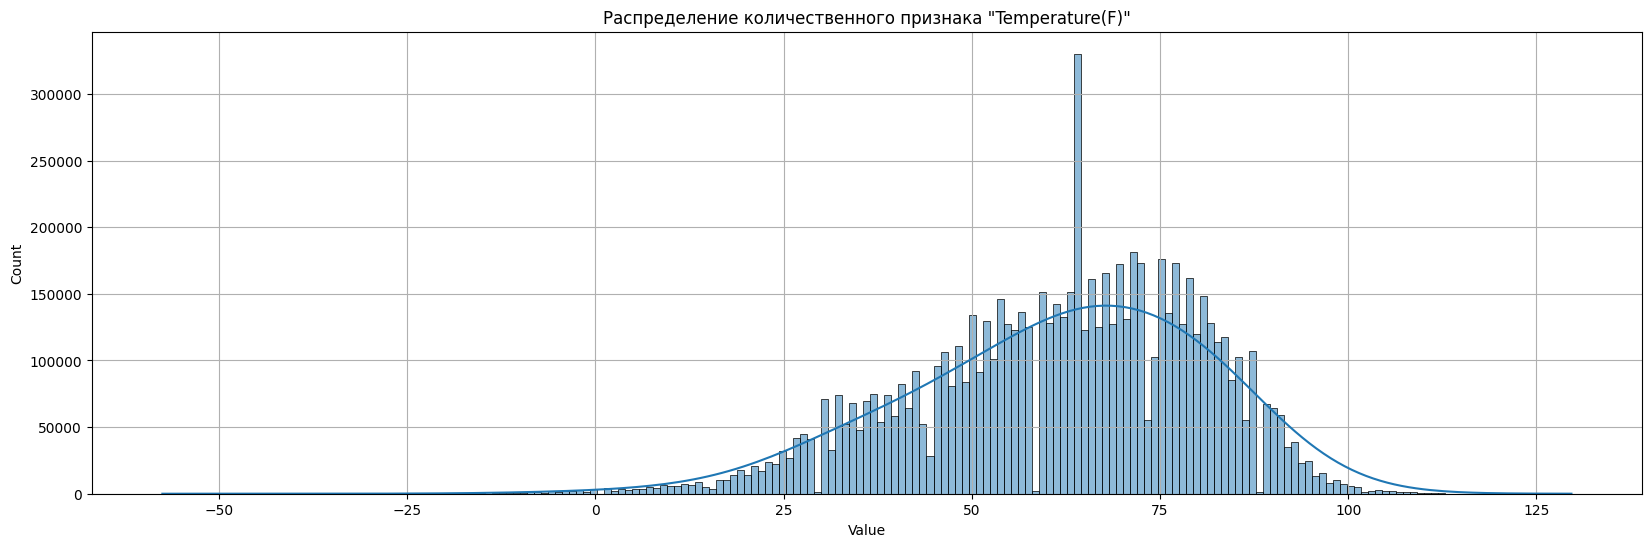

In [38]:
plot_quant_distribution(data=df, column="Temperature(F)")

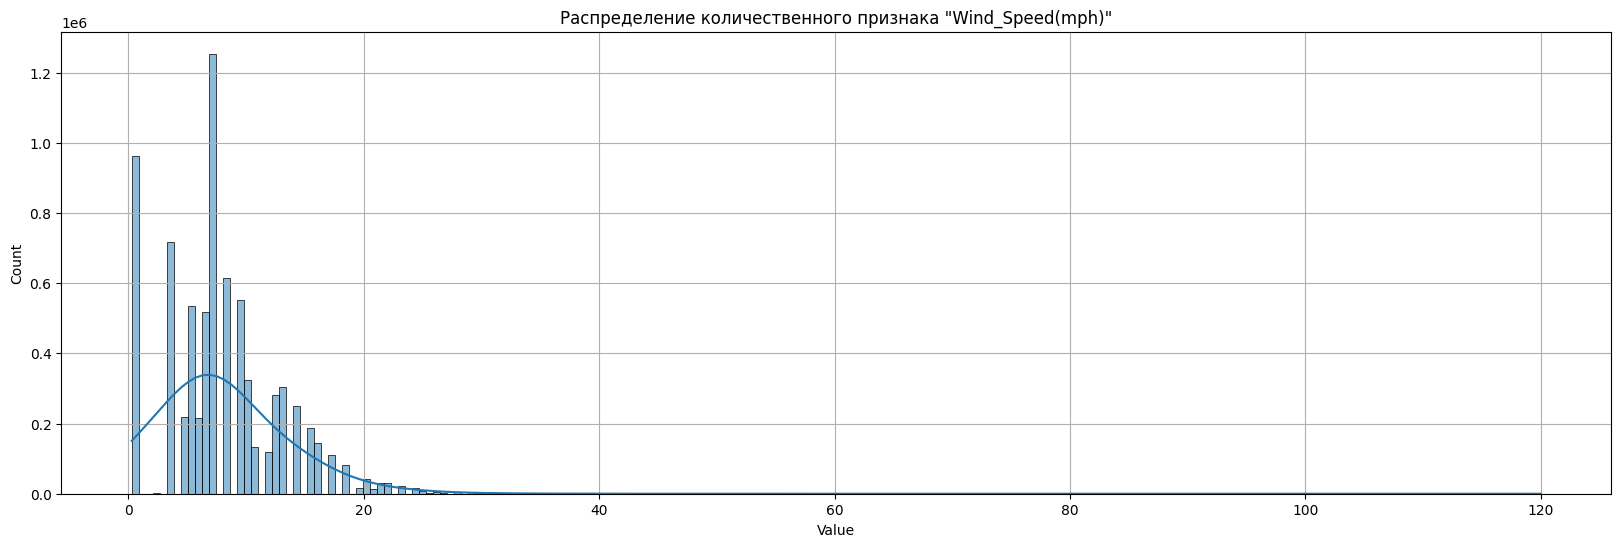

In [39]:
plot_quant_distribution(data=df, column="Wind_Speed(mph)")

На обеих гистограммах виден характерный артефакт заполнения -- узкий пик ровно на значении медианы: у температуры это 163 853 пропущенных значения, заменённые на 64,0°F, у скорости ветра -- 571 233 значений, заменённых на 7,0 миль/ч. Распределение скорости ветра остаётся правосторонне скошенным, что для этой величины естественно, при этом значения свыше 120 миль/ч из данных устранены. Заметьте, что заполнение медианой увеличивает долю «типичного» значения: если далее строится модель, чувствительная к таким пикам, пропуски имеет смысл дополнительно кодировать отдельным бинарным признаком «значение было пропущено».

### Анализ категориальных признаков

Начнём с признаков места: `State`, `City`, `County`, `Zipcode`, `Airport_Code`, `Street`.

Для категориального признака важное свойство -- кардинальность, то есть число различных значений. Посчитаем его для всех категориальных столбцов, не учитывая пропуски.

In [40]:
CARDINALITY_COLUMNS = ["State", "Timezone", "Weather_Condition", "County",
                          "Airport_Code", "City", "Street", "Zipcode",
                          "Wind_Direction"]

for name in CARDINALITY_COLUMNS:
    n = df.filter(col(name).isNotNull()).select(name).distinct().count()
    print(f"{name}: {n} различных значений")

State: 49 различных значений


Timezone: 4 различных значений


Weather_Condition: 144 различных значений


County: 1871 различных значений


Airport_Code: 2045 различных значений


City: 13678 различных значений


Street: 336306 различных значений


Zipcode: 825094 различных значений


Wind_Direction: 24 различных значений


Число различных значений различается на несколько порядков: у штата их 49 (48 штатов плюс округ Колумбия), у часовых поясов -- 4, у метеоусловий -- 144, у направлений ветра -- 24, у округов -- 1 871, у аэропортов -- 2 045, у городов -- 13 678, у названий улиц -- 336 306 и, наконец, у почтовых индексов -- 825 094.

Последнее значение выглядит подозрительно: в США почтовый индекс состоит из пяти цифр, а различных значений получилось больше, чем самих индексов. Причина в том, что значительная часть записей содержит расширенный формат `ZIP+4` -- пять цифр, дефис и ещё четыре цифры. Проверим.

In [41]:
(df.filter(col("Zipcode").isNull()).count(),
 df.filter(col("Zipcode").contains("-")).count(),
 df.filter(length(col("Zipcode")) == 5).count())

(1915, 2268268, 5458211)

Действительно, 2 268 268 значений содержат дефис, а ровно пять символов имеют 5 458 211 значение. Приведём признак к единому формату, оставив первые пять символов: различных значений станет 24 236 вместо 825 094, то есть признак перестанет быть почти уникальным идентификатором строки.

In [42]:
df = df.withColumn("Zipcode", substring(col("Zipcode"), 1, 5))
df.filter(col("Zipcode").isNotNull()).select("Zipcode").distinct().count()

24236

Признак `Street` содержит 336 306 различных значений свободной формы -- названия дорог и шоссе вроде `Bayshore Fwy S`, `Foothill Fwy W` или `Golden State Fwy S` (их видно в первых строках таблицы выше), -- и к тому же в 10 869 записях пропущен. Как категориальный признак для моделирования он почти бесполезен: почти каждая строка даёт собственный уровень, поэтому удалим его. Признаки `City` и `County` сохраним, но учтём их высокую кардинальность при кодировании, а `Airport_Code` заполним явной категорией `Unknown`.

In [43]:
df = df.drop("Street")
df = df.fillna({"Airport_Code": "Unknown"})
df.show(3, truncate=25)

+---------+--------+-------------------+-------------------+---------+----------+-------------------+--------+-----------+-----+-------+----------+------------+-------------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+-----+--------+--------+--------+-------+-------+----------+-------+-----+--------------+------------+--------------+--------------+-----------------+---------------------+------------+
|       ID|Severity|         Start_Time|           End_Time|Start_Lat| Start_Lng|       Distance(mi)|    City|     County|State|Zipcode|  Timezone|Airport_Code|  Weather_Timestamp|Temperature(F)|Wind_Chill(F)|Humidity(%)|Pressure(in)|Visibility(mi)|Wind_Direction|Wind_Speed(mph)|Precipitation(in)|Weather_Condition| Bump|Crossing|Give_Way|Junction|No_Exit|Railway|Roundabout|Station| Stop|Traffic_Signal|Turning_Loop|Sunrise_Sunset|Civil_Twilight|Nautical_Twilight|Astronomical_Twilight|Duration_m

Признак `State` пропусков не содержит и будет полезен для географического среза. Посмотрим распределение десяти самых «аварийных» штатов.

Количество категорий признака State: 49


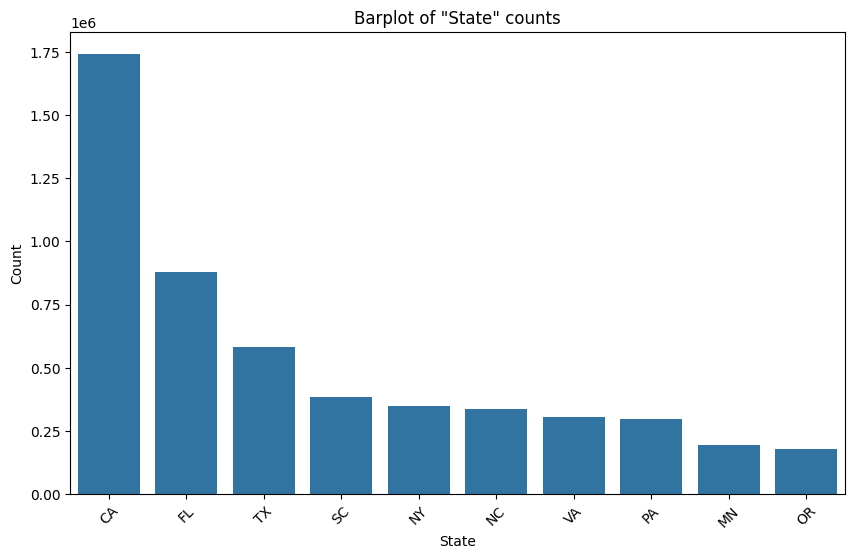

In [44]:
plot_cat_distribution(data=df, column_name="State", top_n=10)

Лидируют Калифорния (1 741 433 записи), Флорида (880 192) и Техас (582 837) -- штаты с наибольшим числом автомобилей и протяжённостью дорог. При этом распределение неравномерно и сильно зависит от покрытия источника данных, что нужно помнить при построении модели: географический признак не равнозначен признаку риска.

Перейдём к метеоусловиям. Признак `Weather_Condition` содержит 144 различных значения при 2,24% пропусков. Заменим пропуски отдельной категорией `Unknown` и посмотрим на распределение.

Число колонок с NULL: 0 (0.00%)


Количество категорий признака Weather_Condition: 145


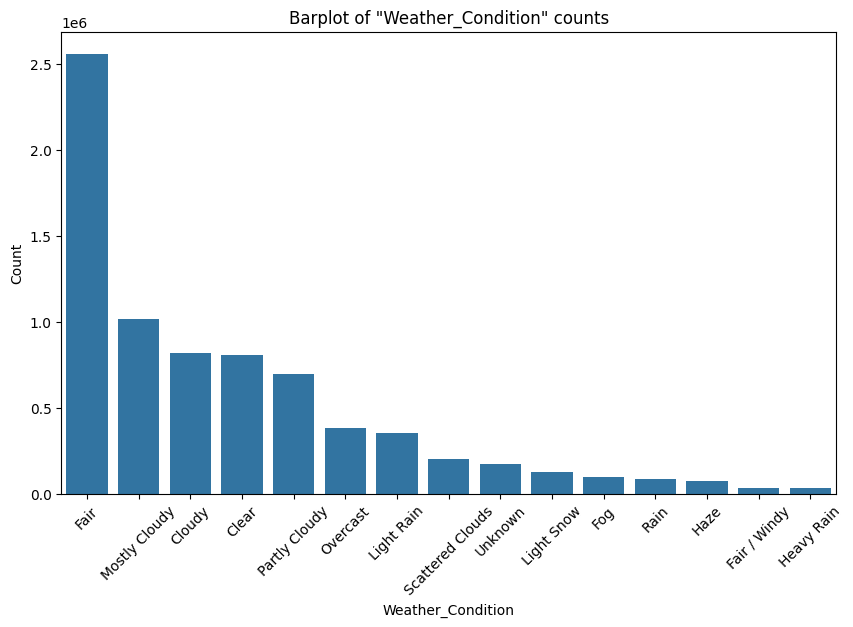

In [45]:
df = df.fillna({"Weather_Condition": "Unknown"})
count_nulls(data=df, column_name="Weather_Condition")
plot_cat_distribution(data=df, column_name="Weather_Condition", top_n=15)

Видно, что основные категории -- `Fair` (2 560 802), `Mostly Cloudy` (1 016 195), `Cloudy` (817 082), `Clear` (808 743) и `Partly Cloudy` (698 972). Хвост же содержит более сотни редких уровней, каждый из которых встречается в долях процента записей; при one-hot кодировании такие уровни создают десятки разреженных столбцов без статистической силы. Оставим категории, встречающиеся чаще 0,1% записей, а прочие сведём в `Other`.

Категорий с долей более 0,1%: 28 из 145


Количество категорий признака Weather_Condition: 29


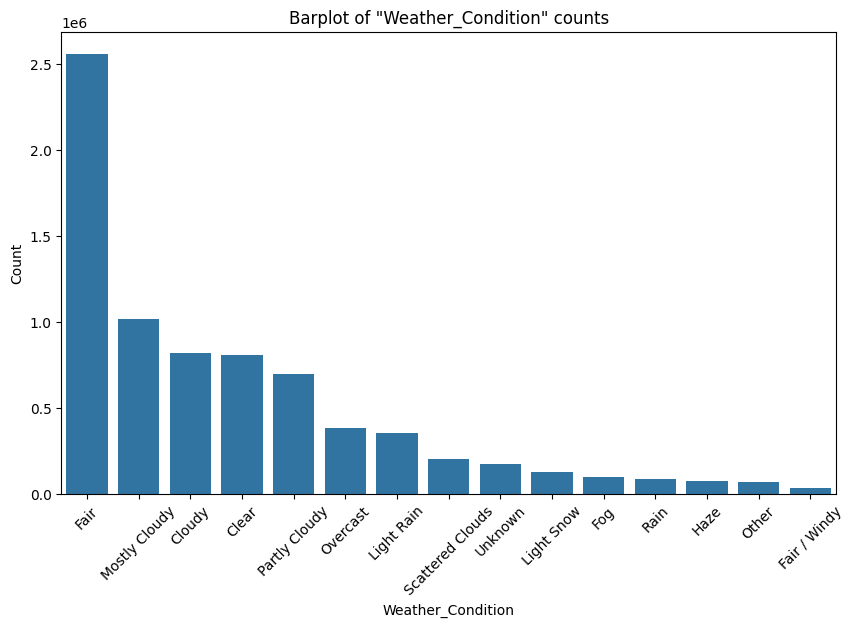

In [46]:
KEEP_CONDITIONS = [
    row[0] for row in
    df.groupBy("Weather_Condition").count()
      .filter(col("count") > 0.001 * total)
      .collect()
]
print(f"Категорий с долей более 0,1%: {len(KEEP_CONDITIONS)} из "
      f"{df.select('Weather_Condition').distinct().count()}")

df = df.withColumn(
    "Weather_Condition",
    when(col("Weather_Condition").isin(KEEP_CONDITIONS), col("Weather_Condition"))
    .otherwise(lit("Other"))
)
plot_cat_distribution(data=df, column_name="Weather_Condition", top_n=15)

Теперь признак содержит 29 уровней: 28 категорий с долей более 0,1% (среди них и `Unknown`, заменивший пропуски) плюс категория `Other`, в которую свелись 69 824 записи с редкими уровнями. При этом исходная кардинальность в 144 значения приводится к содержательному множеству, каждый элемент которого представлен в данных заметным числом наблюдений.

Отдельно разберём направление ветра. Этот категориальный признак «грязный» по-другому: одно и то же направление записано то сокращением, то полным словом, причём штиль встречается и как `CALM`, и как `Calm`. Посмотрим на число различных написаний и на все значения после приведения регистра.

In [47]:
print(f"Различных написаний: {df.select('Wind_Direction').distinct().count()}")
print(f"После trim(lower): {df.select(trim(lower(col('Wind_Direction')))).distinct().count()}")

Различных написаний: 25


После trim(lower): 24


In [48]:
(df.select(trim(lower(col("Wind_Direction"))).alias("wd"))
   .groupBy("wd")
   .count()
   .orderBy("count", ascending=False)
   .show(30, truncate=False))

+--------+-------+
|wd      |count  |
+--------+-------+
|calm    |1330181|
|s       |419989 |
|ssw     |384840 |
|w       |383913 |
|wnw     |378781 |
|nw      |369352 |
|sw      |364470 |
|wsw     |353806 |
|sse     |349110 |
|nnw     |333427 |
|n       |307151 |
|se      |294901 |
|e       |278914 |
|ese     |268311 |
|ne      |258639 |
|ene     |258474 |
|nne     |255311 |
|var     |250566 |
|south   |177375 |
|NULL    |175206 |
|west    |164751 |
|north   |153385 |
|variable|113996 |
|east    |103545 |
+--------+-------+



Приведение регистра оставляет 24 группы вместо 25: объединяются только написания `CALM` (961 624 записей) и `Calm` (368 557), а одна из групп -- это пропуски `NULL` в 175 206 записях. Главная «грязь» в признаке не регистр, а синонимы: четыре полных названия сторон света (`north`, `south`, `east`, `west`) и слово `variable` описывают те же направления, что и сокращения `n`, `s`, `e`, `w` и `var`. Приведём признак к нижнему регистру, удалим обрамляющие пробелы и сольём полные названия с сокращениями -- останется 18 направлений (16 румбов, `calm` и `var`), а пропуски дадут девятнадцатую категорию `unknown`.

In [49]:
WIND_SYNONYMS = {"north": "n", "south": "s", "east": "e", "west": "w",
                  "variable": "var"}

df = df.withColumn("Wind_Direction", trim(lower(col("Wind_Direction"))))
for long_name, short_name in WIND_SYNONYMS.items():
    df = df.withColumn(
        "Wind_Direction",
        when(col("Wind_Direction") == long_name, lit(short_name))
        .otherwise(col("Wind_Direction"))
    )

df = df.fillna({"Wind_Direction": "unknown"})
df.select("Wind_Direction").distinct().count()

19

Количество категорий признака Wind_Direction: 19


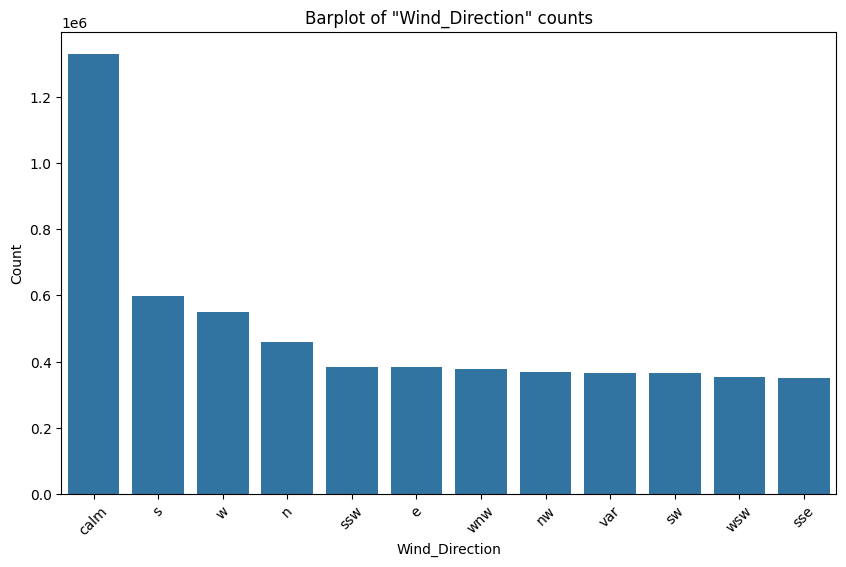

In [50]:
plot_cat_distribution(data=df, column_name="Wind_Direction", top_n=12)

Признак стал компактным и интерпретируемым: самое частое значение -- `calm` (штиль), 1 330 181 запись, что получилось из слияния `CALM` (961 624) и `Calm` (368 557); затем идут `s` (419 989), `ssw` (384 840) и `w` (383 913). Часовые пояса, признаки светового времени суток, города, округа и почтовые индексы заполним явными категориями.

In [51]:
for name in ["Timezone", "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight",
              "Astronomical_Twilight", "City", "County", "Zipcode"]:
    df = df.fillna({name: "Unknown"})

remaining = missing_overview(df)
remaining[remaining["share"] > 0].to_string(index=False)

'           column  nulls    share\nWeather_Timestamp 120228 1.555666'

Пропуски остались только там, где мы сознательно их не заполняли. Заполним и удалим столбец `Weather_Timestamp`: он служебный -- время метеосводки почти совпадает со временем начала происшествия и в моделировании не участвует, а 1,56% его пропусков не несут информации.

In [52]:
df = df.drop("Weather_Timestamp")

### Анализ булевых признаков инфраструктуры

Одиннадцать булевых признаков описывают место события: наличие неровности, пересечения, знака «уступите дорогу», стыка дорог, съезда, переезда, кругового движения, станции, остановки, светофора и петли для разворота. Пропусков в них нет, но есть другая проблема -- почти постоянные признаки. Посчитаем долю истинных значений одним проходом.

In [53]:
BOOLEAN_COLUMNS = [
    "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway", "Roundabout",
    "Station", "Stop", "Traffic_Signal", "Turning_Loop"
]

counters = [count(when(col(name), lit(True))).alias(str(index))
            for index, name in enumerate(BOOLEAN_COLUMNS)]
true_counts = df.agg(*counters).collect()[0].asDict()

shares = pd.DataFrame(
    [(name, int(true_counts[str(index)]), 100.0 * int(true_counts[str(index)]) / total)
     for index, name in enumerate(BOOLEAN_COLUMNS)],
    columns=["column", "true", "share"]
).sort_values("share", ascending=False)
shares.to_string(index=False)

'        column    true     share\nTraffic_Signal 1143772 14.799608\n      Crossing  873763 11.305881\n      Junction  571342  7.392765\n          Stop  214371  2.773810\n       Station  201901  2.612457\n       Railway   66979  0.866661\n      Give_Way   36582  0.473345\n       No_Exit   19545  0.252899\n          Bump    3514  0.045469\n    Roundabout     249  0.003222\n  Turning_Loop       0  0.000000'

Признак `Turning_Loop` не содержит ни одного истинного значения, а `Roundabout` и `Bump` истинны лишь в 249 и 3 514 записях -- доли 0,003% и 0,045%. Нулевая дисперсия таких признаков означает, что они не несут информации для модели, но при этом раздувают матрицу признаков. Удалим признаки, у которых доля истинных значений меньше 0,1%.

In [54]:
LOW_VARIANCE = [name for name, share in zip(shares["column"], shares["share"]) if share < 0.1]
print("Удаляемые признаки:", LOW_VARIANCE)
df = df.drop(*LOW_VARIANCE)
df.show(3, truncate=25)

Удаляемые признаки: ['Bump', 'Roundabout', 'Turning_Loop']


+---------+--------+-------------------+-------------------+---------+----------+-------------------+--------+-----------+-----+-------+----------+------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+--------+--------+--------+-------+-------+-------+-----+--------------+--------------+--------------+-----------------+---------------------+------------+
|       ID|Severity|         Start_Time|           End_Time|Start_Lat| Start_Lng|       Distance(mi)|    City|     County|State|Zipcode|  Timezone|Airport_Code|Temperature(F)|Wind_Chill(F)|Humidity(%)|Pressure(in)|Visibility(mi)|Wind_Direction|Wind_Speed(mph)|Precipitation(in)|Weather_Condition|Crossing|Give_Way|Junction|No_Exit|Railway|Station| Stop|Traffic_Signal|Sunrise_Sunset|Civil_Twilight|Nautical_Twilight|Astronomical_Twilight|Duration_min|
+---------+--------+-------------------+-------------------+---------+----------+---------------

Оставшиеся признаки отражают заметные доли выборок -- от 0,25% для `No_Exit` до 14,8% для `Traffic_Signal` -- и пригодны для моделирования. Проверим это наглядно на признаке наличия светофора.

Количество категорий признака Traffic_Signal: 2


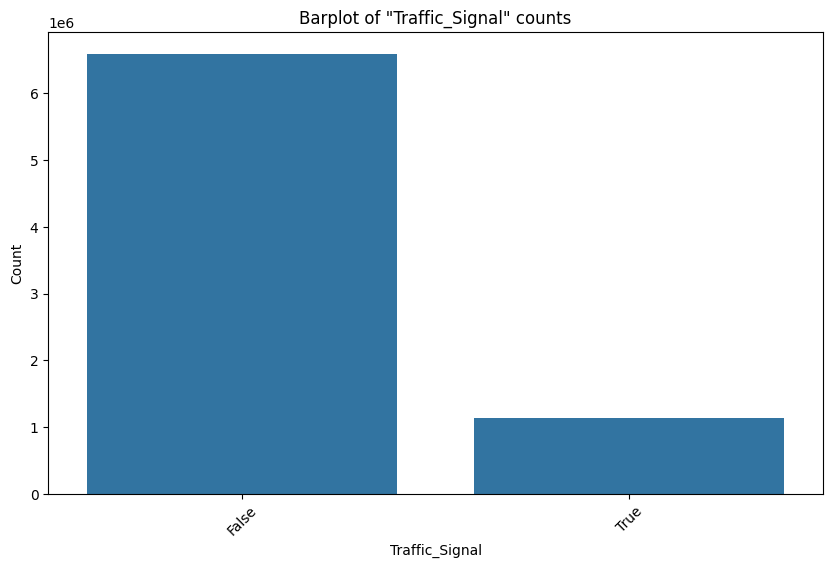

In [55]:
plot_cat_distribution(data=df, column_name="Traffic_Signal")

### Производные признаки из времени суток и календаря

Как и в примере из методических указаний, где год выпуска автомобиля был заменён его возрастом, здесь преобразуем абсолютную временну́ю метку в набор интерпретируемых признаков: номер месяца, день недели и час начала происшествия. Заодно они позволят проверить гипотезу о сезонности и суточной периодичности аварийности.

In [56]:
df = (df
      .withColumn("Month", month(col("Start_Time")))
      .withColumn("Day_Of_Week", dayofweek(col("Start_Time")))
      .withColumn("Hour", hour(col("Start_Time"))))
df.select("Start_Time", "Month", "Day_Of_Week", "Hour").show(5, truncate=False)

+-------------------+-----+-----------+----+
|Start_Time         |Month|Day_Of_Week|Hour|
+-------------------+-----+-----------+----+
|2017-03-23 18:13:37|3    |5          |18  |
|2017-03-23 18:21:08|3    |5          |18  |
|2017-03-23 18:26:23|3    |5          |18  |
|2017-03-23 18:18:05|3    |5          |18  |
|2017-03-23 18:28:37|3    |5          |18  |
+-------------------+-----+-----------+----+
only showing top 5 rows



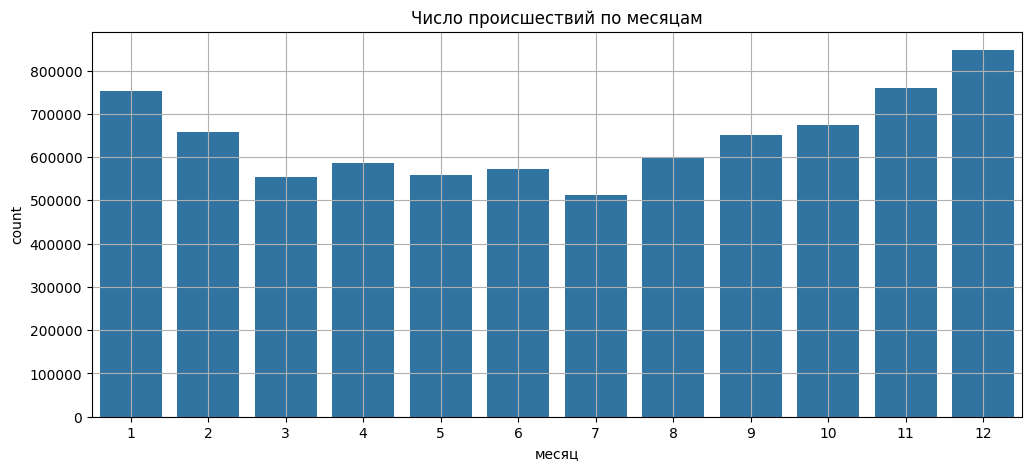

In [57]:
month_counts = df.groupBy("Month").count().orderBy("Month").toPandas()
plt.figure(figsize=(12, 5))
sns.barplot(x="Month", y="count", data=month_counts)
plt.title("Число происшествий по месяцам")
plt.xlabel("месяц")
plt.ylabel("count")
plt.grid(True)
plt.show()

Распределение по месяцам неравномерно: максимумы приходятся на зимние месяцы -- декабрь (847 343), ноябрь (760 165) и январь (751 946), а минимум -- на июль (512 335). Зимний пик аварийности согласуется с влиянием метеоусловий, которое мы наблюдали в признаках `Weather_Condition`, `Temperature(F)` и `Visibility(mi)`. Заметим при этом, что часть неравномерности может отражать не реальный поток происшествий, а покрытие источников данных, поэтому месяц корректнее использовать как категориальный, а не как причинный признак.

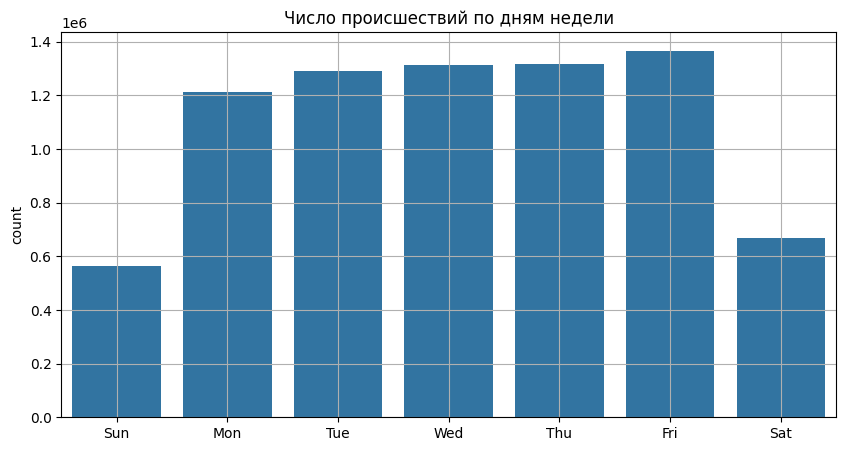

In [58]:
day_counts = df.groupBy("Day_Of_Week").count().orderBy("Day_Of_Week").toPandas()
# В Spark нумерация дней недели начинается с воскресенья: 1 = Sun, ..., 7 = Sat
day_counts["day_name"] = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
plt.figure(figsize=(10, 5))
sns.barplot(x="day_name", y="count", data=day_counts)
plt.title("Число происшествий по дням недели")
plt.xlabel("")
plt.ylabel("count")
plt.grid(True)
plt.show()

Видна выраженная зависимость от дня недели, но характер у неё не дорожный, а «регистратурный»: будни дают от 1 210 921 до 1 366 499 записей, тогда как воскресенье -- всего 562 744, а суббота -- 668 683. В реальном потоке транспорта выходные не бывают втрое «спокойнее» будней; скорее всего, источники данных (операторы и дорожные службы) реже фиксируют незначительные происшествия в выходные. Это типичный пример систематической смещённости (bias) накопленных данных, и признаку дня недели при моделировании нельзя доверять как причинному.

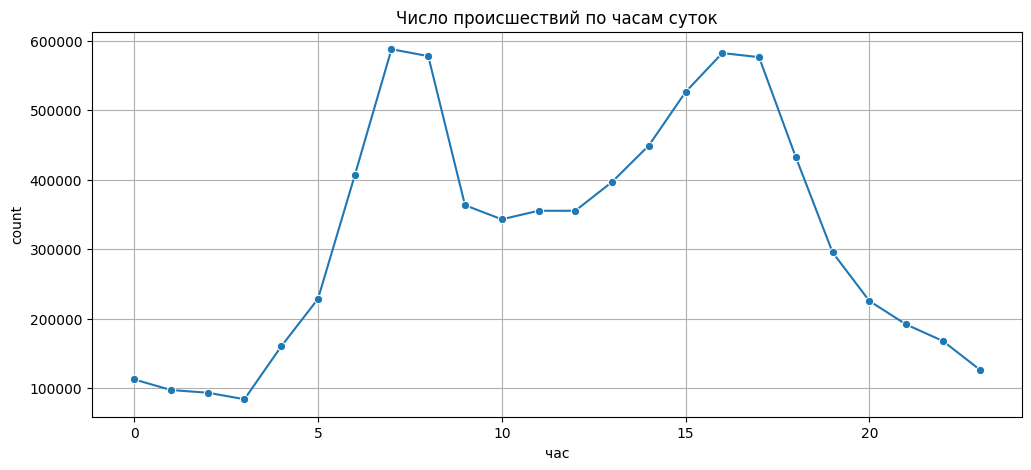

In [59]:
hour_counts = df.groupBy("Hour").count().orderBy("Hour").toPandas()
plt.figure(figsize=(12, 5))
sns.lineplot(x="Hour", y="count", marker="o", data=hour_counts)
plt.title("Число происшествий по часам суток")
plt.xlabel("час")
plt.ylabel("count")
plt.grid(True)
plt.show()

Суточный профиль двугорбый и в точности повторяет профиль трафика: первый пик приходится на 7 часов утра (587 472 записи) и 8 часов (577 576), второй -- на 16 (581 969) и 17 часов (576 015), то есть на часы поездок на работу и с работы. Ночной минимум -- 3 часа (83 863 записей), когда поток транспорта минимален. В отличие от дня недели суточная периодичность выглядит естественной, поэтому час начала происшествия -- содержательный признак для модели.

### Диаграммы «ящик с усами» в разрезе категорий

Выше ящик строился по одному количественному признаку целиком. Такой приём уместен там, где нужно найти абсолютную границу типичного: именно так подбирались пороги винзоризации для `Duration_min` и `Distance(mi)`. Для метеопризнаков он бесполезен по трём причинам: ящик молчит о пропусках (а `approxQuantile` их просто отбрасывает), единичные физически невозможные значения тонут в ширине усов, и, главное, одна «коробочка» смешивает климат десятков штатов и все сезоны сразу.

Правильный ящик для таких признаков -- группированный: количественный признак в разрезе категориального. Введём функцию, которая считает квартили `percentile_approx` прямо на кластере, а в драйвер отдаёт по одной строке на категорию, поэтому объём передаваемых данных не зависит от 7,7 млн строк.

In [60]:
def plot_grouped_boxplots(data: DataFrame,
                          y_column: str,
                          x_column: str,
                          top_n: int = 20) -> None:
    """
    Диаграмма «ящик с усами» для количественного столбца в разрезе
    категориального столбца.

    Args:
        data (DataFrame): DataFrame с данными.
        y_column (str): количественный столбец (ось значений).
        x_column (str): категориальный столбец (ось групп).
        top_n (int): число самых частых категорий для вывода.

    Returns:
        None
    """
    groups = (data.groupBy(x_column).count()
              .orderBy(desc("count"))
              .limit(top_n)
              .toPandas()[x_column].tolist())

    stats = (data.filter(col(x_column).isin(groups))
             .groupBy(x_column)
             .agg(
                 expr(f"percentile_approx(`{y_column}`, "
                      f"array(0.25, 0.5, 0.75), 1000) AS q"),
                 expr(f"min(`{y_column}`) AS min_value"),
                 expr(f"max(`{y_column}`) AS max_value"),
                 expr(f"count(`{y_column}`) AS n"),
             )
             .toPandas())

    stats["q1"] = stats["q"].apply(lambda value: value[0])
    stats["median"] = stats["q"].apply(lambda value: value[1])
    stats["q3"] = stats["q"].apply(lambda value: value[2])
    stats["iqr"] = stats["q3"] - stats["q1"]
    stats["lower"] = [max(q1 - 1.5 * spread, smallest)
                      for q1, spread, smallest in
                      zip(stats["q1"], stats["iqr"], stats["min_value"])]
    stats["upper"] = [min(q3 + 1.5 * spread, largest)
                     for q3, spread, largest in
                     zip(stats["q3"], stats["iqr"], stats["max_value"])]
    stats = stats.sort_values("median")

    print(f"{y_column} по {x_column}: "
          f"медианы групп от {stats['median'].min():.2f} "
          f"до {stats['median'].max():.2f}, "
          f"размах медиан {stats['median'].max() - stats['median'].min():.2f}, "
          f"средний межквартильный размах {stats['iqr'].mean():.2f}")
    print(stats[[x_column, "n", "q1", "median", "q3", "iqr"]]
          .to_string(index=False))

    boxes = [
        {
            "whislo": row.lower,
            "q1": row.q1,
            "med": row.median,
            "q3": row.q3,
            "whishi": row.upper,
            "fliers": [],
        }
        for row in stats.itertuples()
    ]

    fig, ax = plt.subplots(figsize=(20, 6))
    ax.bxp(boxes, positions=range(1, len(boxes) + 1), widths=0.6)
    ax.set_xticks(range(1, len(boxes) + 1))
    ax.set_xticklabels(stats[x_column].astype(str).tolist(), rotation=90)
    ax.set_xlabel(x_column)
    ax.set_ylabel(y_column)
    ax.set_title(f"{y_column} в разрезе {x_column} "
                 f"(точки выбросов не показываются)")
    ax.grid(True)
    plt.show()

Temperature(F) по State: медианы групп от 33.00 до 77.00, размах медиан 44.00, средний межквартильный размах 26.89
State       n   q1    median        q3       iqr
   MN  192084 20.0 33.000000 61.000000 41.000000
   MI  162191 32.0 49.000000 68.000000 36.000000
   OR  179660 39.0 50.000000 63.000000 24.000000
   OH  118115 36.0 52.000000 69.000000 33.000000
   WA  108221 44.0 52.000000 63.000000 19.000000
   IL  168958 35.0 53.000000 71.000000 36.000000
   PA  296620 37.0 54.000000 69.000000 32.000000
   NY  347960 39.0 56.000000 71.000000 32.000000
   NJ  140719 43.0 58.000000 72.000000 29.000000
   MD  140417 44.0 60.799999 70.000000 26.000000
   VA  303301 46.0 62.000000 73.000000 27.000000
   CA 1741433 55.0 63.000000 72.000000 17.000000
   TN  167388 49.0 64.000000 77.000000 28.000000
   NC  338199 50.0 64.000000 75.900002 25.900002
   GA  169234 53.0 65.000000 75.900002 22.900002
   SC  382557 52.0 66.000000 77.000000 25.000000
   TX  582837 59.0 72.000000 82.000000 23.000000
   

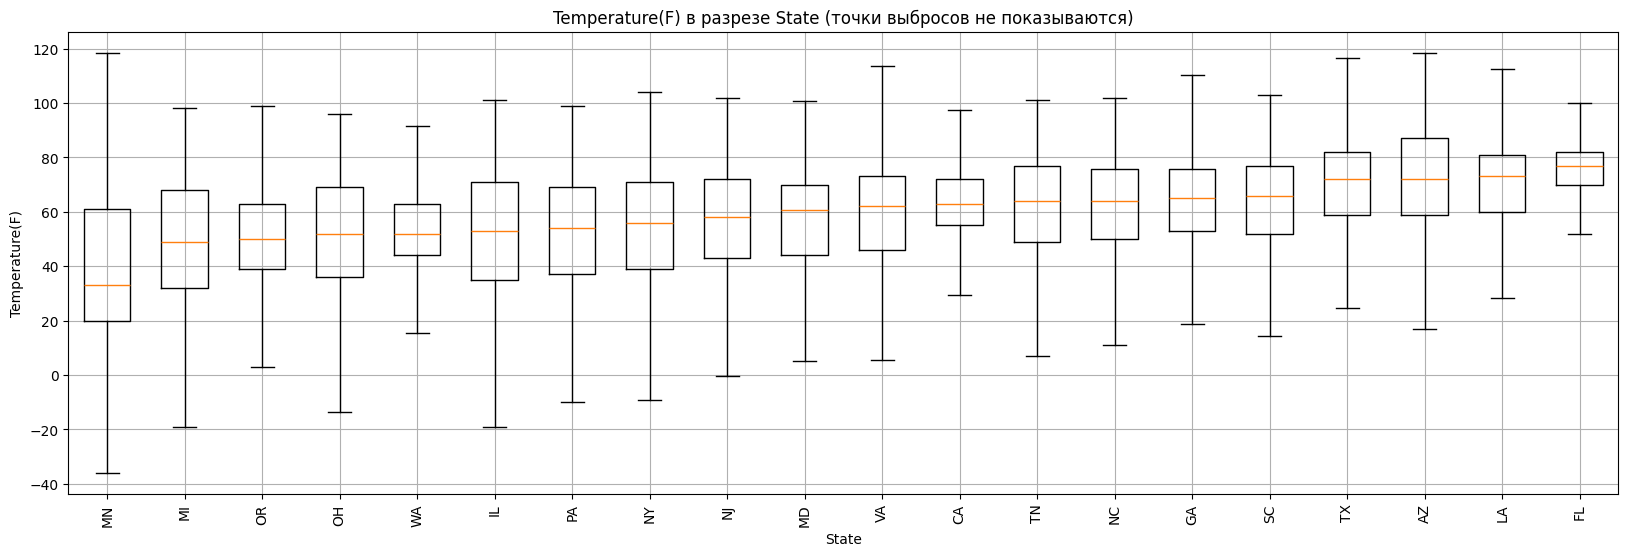

In [61]:
plot_grouped_boxplots(data=df, y_column="Temperature(F)",
                      x_column="State", top_n=20)

Temperature(F) по Month: медианы групп от 46.40 до 80.00, размах медиан 33.60, средний межквартильный размах 19.38
 Month      n        q1    median   q3       iqr
     1 751946 34.000000 46.400002 58.0 24.000000
    12 847343 36.000000 48.000000 59.0 23.000000
     2 658984 34.000000 48.900002 62.0 28.000000
     3 554595 44.599998 55.000000 66.0 21.400002
    11 760165 45.000000 55.900002 66.0 21.000000
     4 587300 53.000000 62.599998 72.0 19.000000
    10 675130 55.900002 65.000000 75.0 19.099998
     5 558176 61.000000 70.000000 79.0 18.000000
     9 651381 66.000000 74.000000 82.0 16.000000
     6 571373 69.000000 77.000000 84.0 15.000000
     8 599666 72.000000 79.000000 86.0 14.000000
     7 512335 73.000000 80.000000 87.0 14.000000


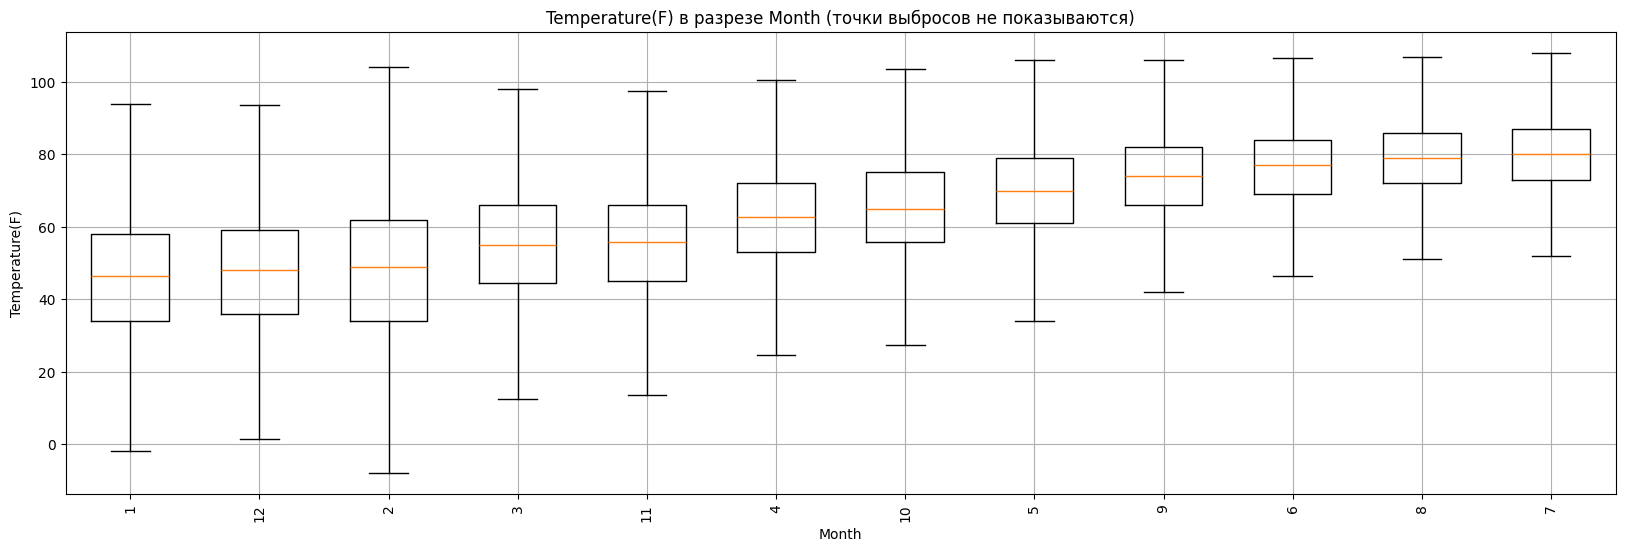

In [62]:
plot_grouped_boxplots(data=df, y_column="Temperature(F)",
                      x_column="Month", top_n=12)

Wind_Speed(mph) по Month: медианы групп от 7.00 до 8.00, размах медиан 1.00, средний межквартильный размах 5.59
 Month      n  q1  median   q3  iqr
    12 847343 3.5     7.0 10.0  6.5
     1 751946 4.6     7.0 10.0  5.4
     6 571373 5.0     7.0 10.0  5.0
     9 651381 4.6     7.0  9.0  4.4
     8 599666 4.6     7.0  9.0  4.4
    11 760165 3.5     7.0  9.2  5.7
    10 675130 4.6     7.0  9.2  4.6
     7 512335 5.0     7.0  9.2  4.2
     2 658984 5.0     7.0 11.5  6.5
     4 587300 5.8     8.0 12.7  6.9
     3 554595 5.0     8.0 12.0  7.0
     5 558176 5.0     8.0 11.5  6.5


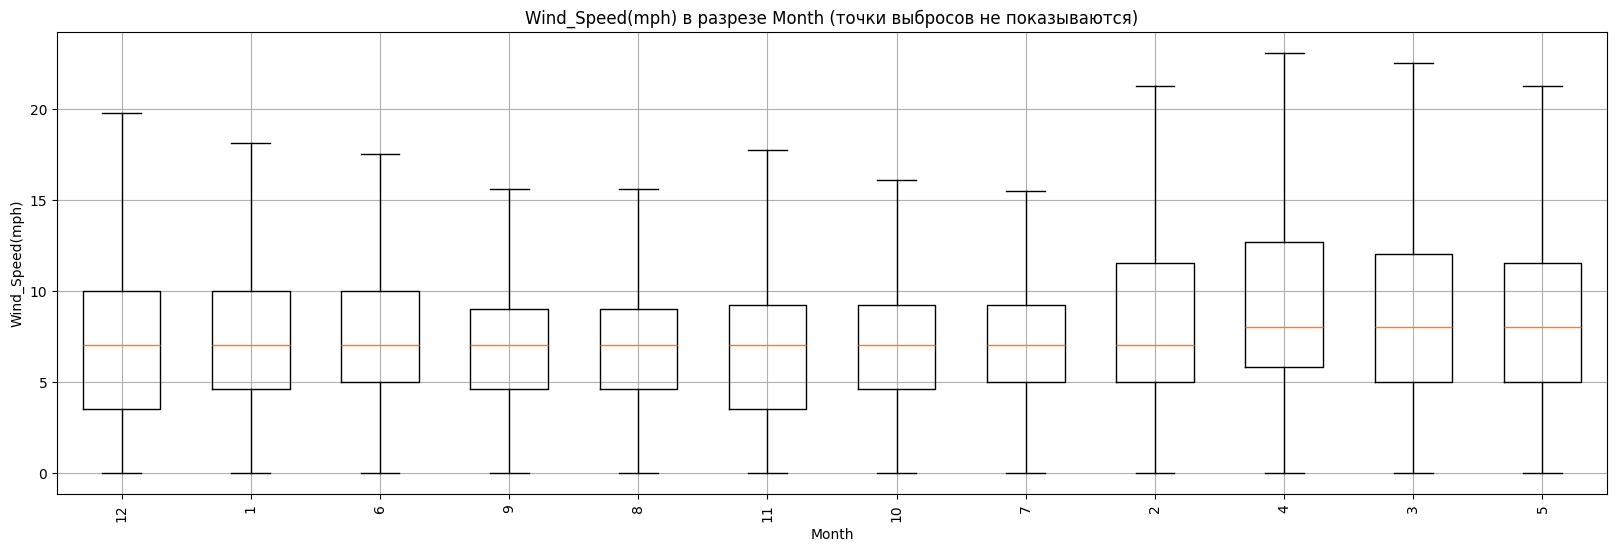

In [63]:
plot_grouped_boxplots(data=df, y_column="Wind_Speed(mph)",
                      x_column="Month", top_n=12)

Duration_min по Severity: медианы групп от 44.40 до 128.33, размах медиан 83.93, средний межквартильный размах 111.34
 Severity       n        q1     median         q3        iqr
        3 1299337 29.616667  44.400002  60.000000  30.383333
        1   67366 29.666666  44.750000  59.716667  30.050001
        2 6156981 44.433334  77.566666 129.350006  84.916672
        4  204710 60.000000 128.333328 360.000000 300.000000


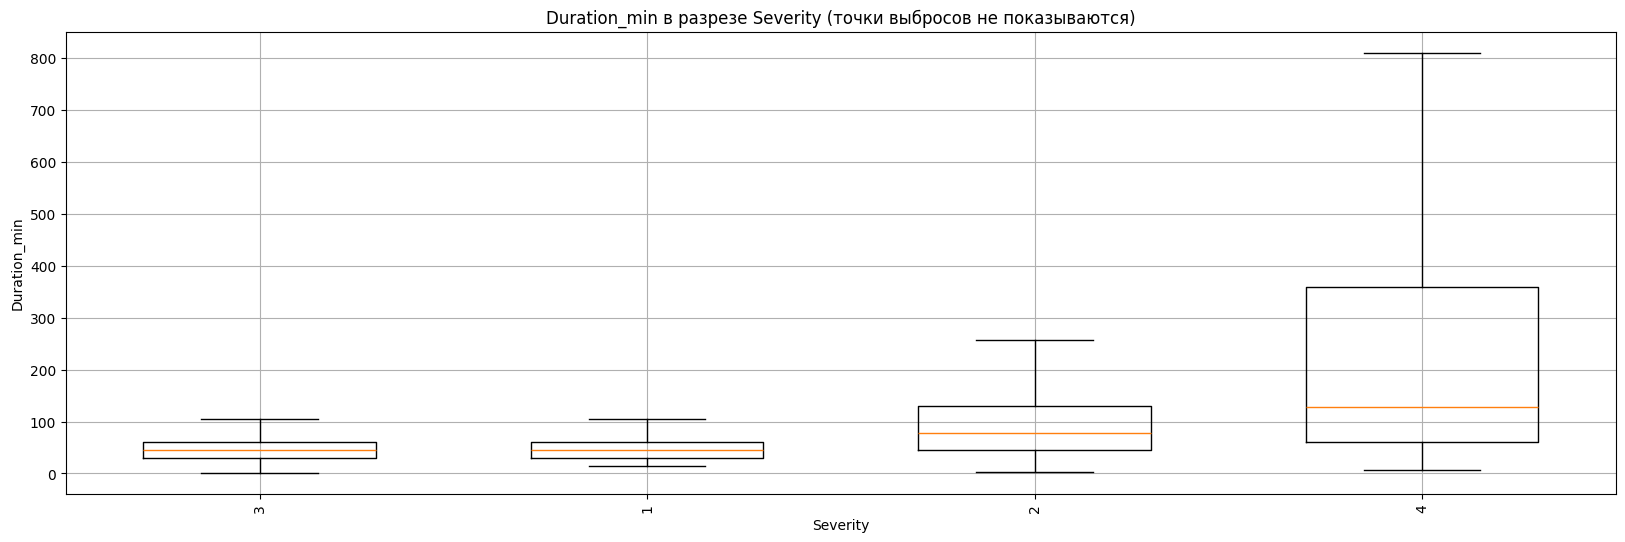

In [64]:
plot_grouped_boxplots(data=df, y_column="Duration_min",
                      x_column="Severity", top_n=4)

### Расчет корреляции между количественными признаками

Перед вычислением корреляций зафиксируем в памяти уже полностью подготовленный датафрейм. К этому месту логический план содержит десятки последовательных преобразований, а корреляции вычисляются многими небольшими запросами подряд; кэширование результата преобразований освобождает планировщик от перестроения этого плана на каждом запросе.

In [65]:
df = df.cache()
df.count()

7728394

Введём функцию вычисления и визуализации корреляционной матрицы. Для пар признаков вычисление симметрично, поэтому достаточно оценить верхний треугольник матрицы, а диагональ всегда равна единице.

In [66]:
def compute_and_visualize_correlation_matrix(data: DataFrame,
                                             columns: list[str]) -> None:
    """
    Вычисляет и визуализирует корреляционную матрицу для указанных
    колонок в DataFrame PySpark.

    Args:
        data (DataFrame): DataFrame PySpark.
        columns (list[str]): Список колонок для вычисления корреляции.

    Returns:
        None
    """
    # Вычисление корреляционной матрицы
    corr_matrix = {c1: {c2: 1.0 for c2 in columns} for c1 in columns}
    for index, col1 in enumerate(columns):
        for col2 in columns[index + 1:]:
            corr_value = data.select(corr(col1, col2)).collect()[0][0]
            corr_matrix[col1][col2] = corr_value
            corr_matrix[col2][col1] = corr_value

    # Преобразование корреляционной матрицы в DataFrame Pandas для визуализации
    corr_matrix_pd = pd.DataFrame(corr_matrix)

    # Числа самых сильных связей проще прочитать в тексте, чем на тепловой карте
    pairs = pd.DataFrame(
        [(col1, col2, corr_matrix[col1][col2])
         for index, col1 in enumerate(columns) for col2 in columns[index + 1:]],
        columns=["column_1", "column_2", "corr"]
    )
    pairs["abs_corr"] = pairs["corr"].abs()
    print(pairs.sort_values("abs_corr", ascending=False)
          .head(8)
          .to_string(index=False))

    # Построение и визуализация корреляционной матрицы
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix_pd, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.show()

      column_1          column_2      corr  abs_corr
Temperature(F)     Wind_Chill(F)  0.913762  0.913762
   Humidity(%)    Visibility(mi) -0.381457  0.381457
Temperature(F)       Humidity(%) -0.330406  0.330406
 Wind_Chill(F)       Humidity(%) -0.272091  0.272091
Visibility(mi) Precipitation(in) -0.225475  0.225475
Temperature(F)    Visibility(mi)  0.216514  0.216514
 Wind_Chill(F)    Visibility(mi)  0.204207  0.204207
   Humidity(%)   Wind_Speed(mph) -0.173481  0.173481


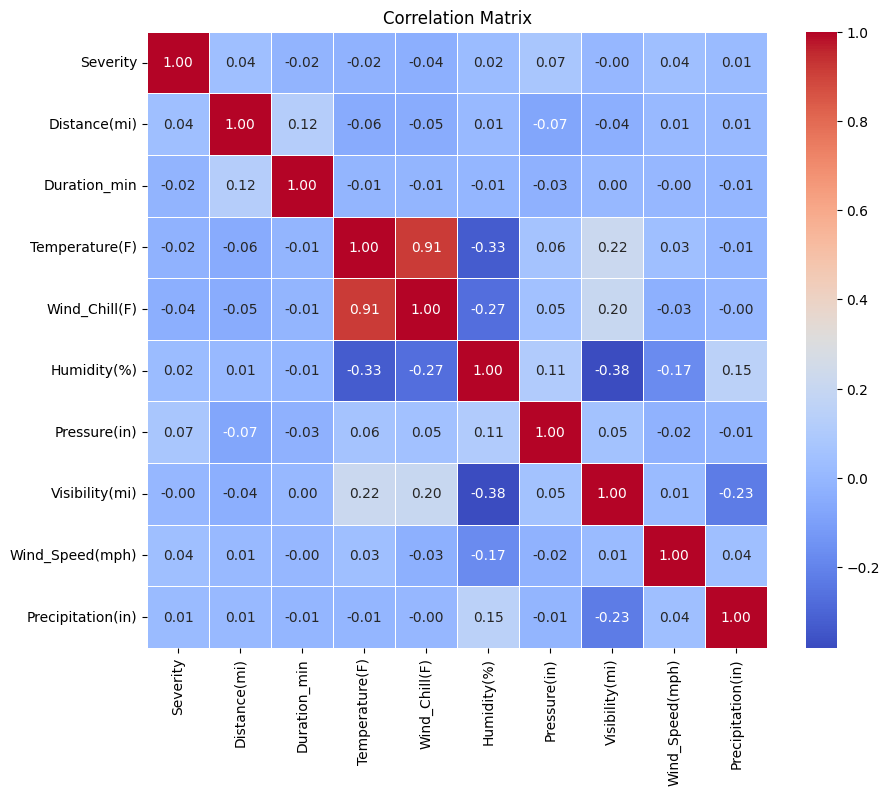

In [67]:
compute_and_visualize_correlation_matrix(
    data=df, columns=[
        "Severity", "Distance(mi)", "Duration_min", "Temperature(F)",
        "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
        "Wind_Speed(mph)", "Precipitation(in)"
    ]
)

Корреляционная матрица даёт три наблюдения.

Первое: метеопризнаки связаны между собой заметно сильнее, чем с целью моделирования. Самые тесные зависимости -- между температурой и ощущаемой температурой с учётом ветра ($r = 0{,}91$), влажностью и видимостью ($r = -0{,}38$), температурой и влажностью ($r = -0{,}33$), видимостью и количеством осадков ($r = -0{,}23$). Знаки согласуются с физикой: чем выше влажность и чем ниже температура, тем хуже видимость, а осадки ухудшают её дополнительно. Высокая корреляция пары `Temperature(F)` -- `Wind_Chill(F)` подтверждает избыточность признака `Wind_Chill(F)`: ощущаемая температура вычисляется из температуры и скорости ветра, поэтому для модели достаточно одного из двух.

Второе: длительность происшествия почти не связана с метеоусловиями (по модулю $|r| < 0{,}03$) и умеренно связана с протяжённостью перекрытого участка ($r = 0{,}12$).

Третье: тяжесть происшествия тоже слабо коррелирует с численными признаками -- сильнее всего с давлением воздуха ($r = 0{,}07$), затем со скоростью ветра ($r = 0{,}04$), протяжённостью участка ($r = 0{,}04$) и влажностью ($r = 0{,}02$), а с собственной длительностью связь почти нулевая и даже отрицательная ($r = -0{,}02$).

Практический вывод для постановки задач моделирования: линейные корреляции -- лишь первый, грубый отбор связей, и на одних количественных признаках предсказание цели будет слабым; основную информацию следует искать в категориальных и производных признаках (место, время, метеоусловия) и во взаимодействиях между ними. Диагональ матрицы равна единице по определению.

Посмотрим, сколько объектов и сколько столбцов осталось после всех преобразований.

In [68]:
df.count()

7728394

In [69]:
df.printSchema()

root
 |-- ID: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- Distance(mi): double (nullable = true)
 |-- City: string (nullable = false)
 |-- County: string (nullable = false)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = false)
 |-- Timezone: string (nullable = false)
 |-- Airport_Code: string (nullable = false)
 |-- Temperature(F): float (nullable = false)
 |-- Wind_Chill(F): float (nullable = false)
 |-- Humidity(%): float (nullable = false)
 |-- Pressure(in): float (nullable = false)
 |-- Visibility(mi): float (nullable = false)
 |-- Wind_Direction: string (nullable = false)
 |-- Wind_Speed(mph): float (nullable = false)
 |-- Precipitation(in): float (nullable = false)
 |-- Weather_Condition: string (nullable = false)
 |-- Crossing: boolean (nullable = true)
 |-- Give

Строк стало ровно столько же, сколько было -- 7 728 394: все найденные аномалии мы обрабатывали заменой значений (виндзоризация, замена на медиану, нормализация формата), а не удалением записей. Это осознанный выбор: при объёме данных в 7,7 млн строк потеря нескольких тысяч записей не улучшила бы модель, зато сама ошибка в целостности признака могла бы остаться незамеченной. Число столбцов сократилось с 40 до 38: удалены `Street`, `Weather_Timestamp` и три почти константных булевых признака (`Bump`, `Roundabout`, `Turning_Loop`), добавлены `Month`, `Day_Of_Week`, `Hour`.

Сохраняем очищенный и обработанный датафрейм на диск.

In [70]:
# Сохранение DataFrame в виде таблицы
df.writeTo("otpushchennikov_us_accidents_processed").using("iceberg").create()

После успешной записи можно посмотреть, какие таблицы входят в базу данных.

In [71]:
for table in spark.catalog.listTables():
    print(table.name)

otpushchennikov_us_accidents_processed
otpushchennikov_us_accidents


Обратите внимание, что при необходимости созданные базу данных и таблицу можно удалить следующими командами.

In [72]:
# spark.sql("DROP TABLE spark_catalog.otpushchennikov_database.otpushchennikov_us_accidents_processed")
# spark.sql("DROP TABLE spark_catalog.otpushchennikov_database.otpushchennikov_us_accidents")
# spark.sql("DROP DATABASE spark_catalog.otpushchennikov_database")

Очищаем кэш `Spark` и останавливаем сессию.

In [73]:
spark.catalog.clearCache()
spark.stop()